In [ ]:
#====Figure 1=====

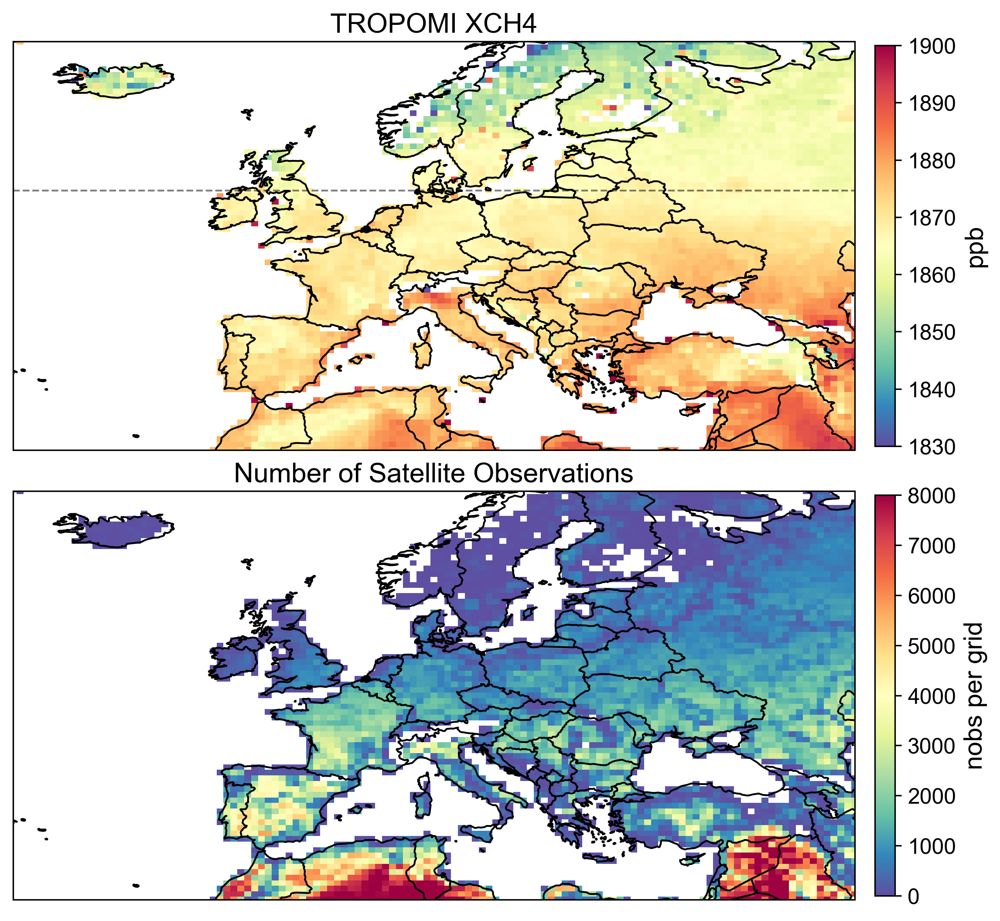

图片已保存：D:\blended_original\2019lrs\yearly_gridded\S5P_BLND_XCH4_mean_nobs_2019_2023.png


In [1]:
import os

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib
import cartopy.crs as ccrs
import cartopy.feature as cfeature


matplotlib.rcParams["font.family"] = "Arial"


# =========================================================
# 基本设置
# =========================================================
YEARLY_FOLDER = (
    r"D:\blended_original\2019\yearly_gridded"
)

YEARS = range(2019, 2024)

res_lat = 0.5
res_lon = 0.625


# =========================================================
# 读取年度文件
# =========================================================
annual_datasets = []

for year in YEARS:

    file_path = os.path.join(
        YEARLY_FOLDER,
        f"S5P_BLND_CH4_gridded_{year}.nc",
    )

    if not os.path.isfile(file_path):
        raise FileNotFoundError(
            f"找不到年度文件：{file_path}"
        )

    with xr.open_dataset(file_path) as ds:
        annual_ds = ds[
            [
                "xch4_blended_mean",
                "observation_count",
            ]
        ].load()

    annual_ds = annual_ds.expand_dims(
        year=[year]
    )

    annual_datasets.append(
        annual_ds
    )


combined = xr.concat(
    annual_datasets,
    dim="year",
)


# =========================================================
# =========================================================
blnd_mean = combined[
    "xch4_blended_mean"
].mean(
    dim="year",
    skipna=True,
)

mean_grid_count = combined[
    "observation_count"
].mean(
    dim="year",
    skipna=True,
)


# 每个网格实际包含多少个年份
available_years = combined[
    "xch4_blended_mean"
].count(
    dim="year"
)

REQUIRE_ALL_FIVE_YEARS = False

if REQUIRE_ALL_FIVE_YEARS:

    complete_mask = (
        available_years == len(YEARS)
    )

    blnd_mean = blnd_mean.where(
        complete_mask
    )

    mean_grid_count = (
        mean_grid_count.where(
            complete_mask
        )
    )
# =========================================================
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(10, 9),
    dpi=300,
    subplot_kw={
        "projection": ccrs.PlateCarree()
    },
)


lon_min = -30 + 3 * res_lon
lon_max = 50 - 3 * res_lon
lat_min = 30 + 3 * res_lat
lat_max = 70 - 3 * res_lat

# =========================================================
# =========================================================
ax1 = axes[0]

ax1.add_feature(
    cfeature.COASTLINE
)

ax1.add_feature(
    cfeature.BORDERS
)

ax1.set_extent(
    [
        lon_min,
        lon_max,
        lat_min,
        lat_max,
    ],
    crs=ccrs.PlateCarree(),
)

im1 = blnd_mean.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    cmap="Spectral_r",
    vmin=1830,
    vmax=1900,
    add_colorbar=False,
)

ax1.plot(
    [lon_min, lon_max],
    [55, 55],
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.5,
    transform=ccrs.PlateCarree(),
    zorder=5,
)

ax1.set_title(
    "TROPOMI XCH4",
    fontsize=15,
    pad=5,
)

cb1 = fig.colorbar(
    im1,
    ax=ax1,
    orientation="vertical",
    pad=0.02,
    shrink=0.9,
)

cb1.ax.tick_params(
    labelsize="large"
)

cb1.set_label(
    "ppb",
    fontsize=14,
)

# =========================================================
# =========================================================
ax2 = axes[1]

ax2.add_feature(
    cfeature.COASTLINE
)

ax2.add_feature(
    cfeature.BORDERS
)

ax2.set_extent(
    [
        lon_min,
        lon_max,
        lat_min,
        lat_max,
    ],
    crs=ccrs.PlateCarree(),
)

im2 = mean_grid_count.plot(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap="Spectral_r",
    vmin=0,
    vmax=8000,
    add_colorbar=False,
)

ax2.set_title(
    "Number of Satellite Observations",
    fontsize=15,
    pad=5,
)

cb2 = fig.colorbar(
    im2,
    ax=ax2,
    orientation="vertical",
    pad=0.02,
    shrink=0.9,
)

cb2.ax.tick_params(
    labelsize="large"
)

cb2.set_label(
    "nobs per grid",
    fontsize=14,
)


plt.subplots_adjust(
    hspace=0.01,
    top=0.88,
    bottom=0.12,
)

output_figure = os.path.join(
    YEARLY_FOLDER,
    "S5P_BLND_XCH4_mean_nobs_2019_2023.png",
)

plt.savefig(
    output_figure,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(
    f"图片已保存：{output_figure}"
)

In [ ]:
#===Figure 2====

正在读取：F:\Inv_EU\icos_diag\2019\Inv_2019_0000_merged.csv
正在读取：F:\Inv_EU\icos_diag\2020\Inv_2020_0000_merged.csv
正在读取：F:\Inv_EU\icos_diag\2021\Inv_2021_0000_merged.csv
正在读取：F:\Inv_EU\icos_diag\2022\Inv_2022_0000_merged.csv
正在读取：F:\Inv_EU\icos_diag\2023\Inv_2023_0000_merged.csv

非山地站统计：
TYPE     OBS_avg   LAT   LON  data_count  year_count station_name
SBIR 2001.902606 58.39  8.25        1179           4          BIR
SCBW 2128.585445 51.97  4.93         819           3          CBW
SGAT 2029.218272 53.07 11.44        1739           5          GAT
SHEL 2042.223013 54.18  7.88        1095           4          HEL
SHPB 2017.900379 47.80 11.02        1796           5          HPB
SHTM 2003.812308 56.10 13.42        1757           5          HTM
SHUN 2058.140044 46.96 16.65         179           1          HUN
SIPR 2069.939112 45.81  8.64        1814           5          IPR
SJUE 2043.631274 50.91  6.41        1493           5          JUE
SKIT 2027.254002 49.09  8.42        1776           5    

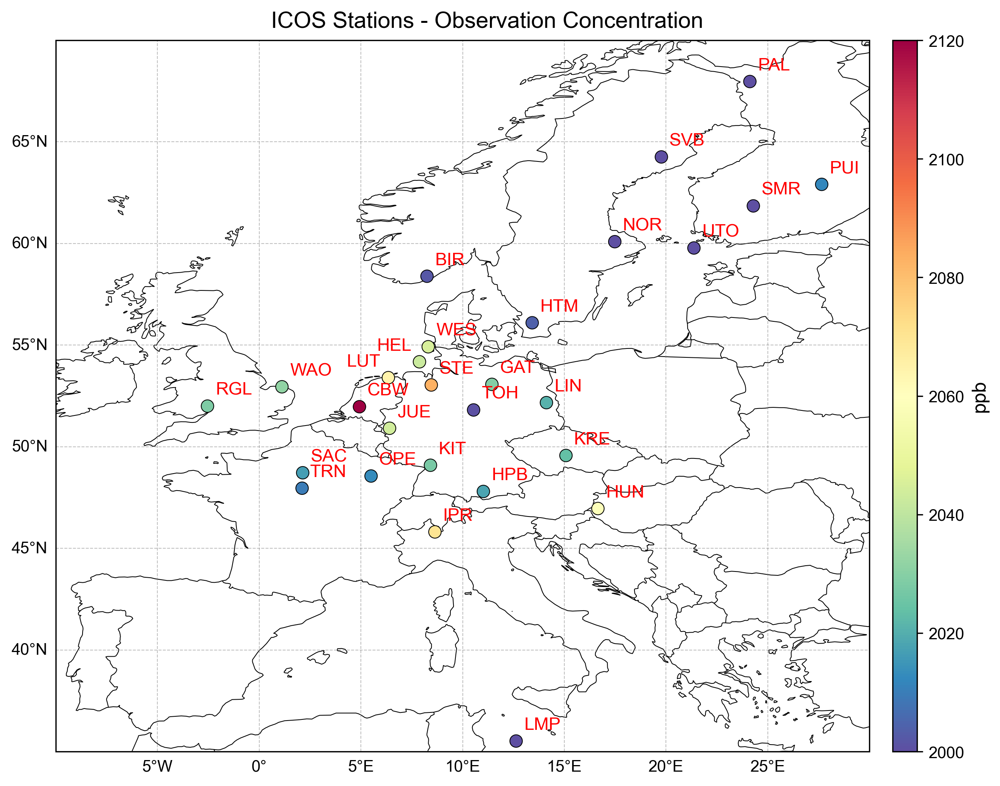

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from mpl_toolkits.axes_grid1 import make_axes_locatable


# ============================================================
# ============================================================

years = range(2019, 2024)

base_root = r'F:\Inv_EU\icos_diag'

target_timezone = 'Europe/Berlin'

MOUNTAIN_SITES = {
    'SCMN',
    'SJFJ',
    'SOXK',
    'SPRS',
    'SPUY',
    'SSSL',
    'SZSF'
}

all_selected_df = []

# ============================================================
# ============================================================

for year in years:

    file_path = os.path.join(
        base_root,
        str(year),
        f'Inv_{year}_0000_merged.csv'
    )

    if not os.path.isfile(file_path):
        print(f'文件不存在：{file_path}')
        continue

    print(f'正在读取：{file_path}')

    df = pd.read_csv(file_path)


    # --------------------------------------------------------
    # --------------------------------------------------------

    df['HHMM'] = (
        pd.to_numeric(df['HHMM'], errors='coerce')
        .astype('Int64')
        .astype(str)
        .str.zfill(4)
    )

    df['YYYYMMDD'] = (
        pd.to_numeric(df['YYYYMMDD'], errors='coerce')
        .astype('Int64')
        .astype(str)
        .str.zfill(8)
    )

    datetime_string = (
        df['YYYYMMDD']
        + ' '
        + df['HHMM'].str[:2]
        + ':'
        + df['HHMM'].str[2:]
    )

    df['UTC_TIME'] = pd.to_datetime(
        datetime_string,
        format='%Y%m%d %H:%M',
        utc=True,
        errors='coerce'
    )

    df = df.dropna(
        subset=['UTC_TIME']
    ).copy()

    df['local_time'] = (
        df['UTC_TIME']
        .dt.tz_convert(target_timezone)
    )

    df.set_index(
        'local_time',
        inplace=True
    )

    # --------------------------------------------------------
    # --------------------------------------------------------

    filtered_df = df.between_time(
        '10:00',
        '16:00',
        inclusive='both'
    ).copy()


    # --------------------------------------------------------
    # --------------------------------------------------------

    numeric_columns = [
        'TRA_001',
        'OBS',
        'PRESS',
        'LAT',
        'LON'
    ]

    for column in numeric_columns:

        filtered_df[column] = pd.to_numeric(
            filtered_df[column],
            errors='coerce'
        )

    filtered_df = filtered_df.dropna(
        subset=[
            'TYPE',
            'PRESS',
            'OBS',
            'LAT',
            'LON'
        ]
    ).copy()


    # --------------------------------------------------------
    # --------------------------------------------------------

    filtered_df = filtered_df[
        ~filtered_df['TYPE'].astype(str).isin(
            MOUNTAIN_SITES
        )
    ].copy()


    if filtered_df.empty:
        continue

    filtered_df['TRA_001'] *= 1e9
    filtered_df['DATE'] = filtered_df.index.date
    # --------------------------------------------------------
    # --------------------------------------------------------

    result_df = (
        filtered_df
        .groupby(
            ['TYPE', 'PRESS', 'DATE']
        )[
            ['TRA_001', 'OBS', 'LAT', 'LON']
        ]
        .mean()
        .reset_index()
    )

    selected_df = result_df.loc[
        result_df
        .groupby(
            ['TYPE', 'DATE']
        )['PRESS']
        .idxmax()
    ].copy()

    selected_df.rename(
        columns={'DATE': 'time'},
        inplace=True
    )

    selected_df['YEAR'] = year

    all_selected_df.append(
        selected_df
    )
# ============================================================
# ============================================================

if not all_selected_df:

    raise RuntimeError(
        '2019-2023没有有效数据'
    )

all_selected_df = pd.concat(
    all_selected_df,
    ignore_index=True
)

# ============================================================
# ============================================================

station_summary = (
    all_selected_df
    .groupby(
        'TYPE',
        as_index=False
    )
    .agg(
        OBS_avg=('OBS', 'mean'),
        LAT=('LAT', 'mean'),
        LON=('LON', 'mean'),
        data_count=('OBS', 'count'),
        year_count=('YEAR', 'nunique')
    )
)

station_summary = station_summary.dropna(
    subset=[
        'OBS_avg',
        'LAT',
        'LON'
    ]
).copy()

station_summary['station_name'] = (
    station_summary['TYPE']
    .astype(str)
    .str[1:]
)


lats = (
    station_summary['LAT']
    .round(2)
    .to_numpy()
)

lons = (
    station_summary['LON']
    .round(2)
    .to_numpy()
)

obs_values = (
    station_summary['OBS_avg']
    .to_numpy()
)

station_names = (
    station_summary['station_name']
    .to_numpy()
)


print('\n非山地站统计：')

print(
    station_summary
    .sort_values('TYPE')
    .to_string(index=False)
)

print(
    '\n非山地站数量：',
    len(station_summary)
)


# ============================================================
# ============================================================

fig = plt.figure(
    figsize=(10, 7),
    dpi=300
)

ax = fig.add_subplot(
    111,
    projection=ccrs.PlateCarree()
)

ax.set_extent(
    [-10, 30, 35, 70],
    crs=ccrs.PlateCarree()
)

ax.add_feature(
    cfeature.COASTLINE,
    linewidth=0.5
)

ax.add_feature(
    cfeature.BORDERS,
    linewidth=0.5
)

gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
)

gl.top_labels = False
gl.right_labels = False

gl.xlabel_style = {
    'size': 10,
    'color': 'black'
}

gl.ylabel_style = {
    'size': 10,
    'color': 'black'
}


# ============================================================
# ============================================================

sc = ax.scatter(
    lons,
    lats,
    c=obs_values,
    cmap='Spectral_r',
    s=60,
    transform=ccrs.PlateCarree(),
    edgecolors='k',
    linewidth=0.5,
    vmin=2000,
    vmax=2120,
    zorder=4
)


# colorbar
divider = make_axes_locatable(ax)

cbar_ax = divider.append_axes(
    'right',
    size='3%',
    pad=0.2,
    axes_class=plt.Axes
)

cbar = plt.colorbar(
    sc,
    cax=cbar_ax
)

cbar.set_label(
    'ppb',
    fontsize=12
)

cbar.ax.tick_params(
    labelsize=10
)

# ============================================================
# ============================================================

special_label_offsets = {
    'HEL': (-5, 5, 'right', 'bottom'),
    'LUT': (-5, 5, 'right', 'bottom')
}


for lon, lat, name in zip(
    lons,
    lats,
    station_names
):

    if name in special_label_offsets:

        x_offset, y_offset, ha, va = (
            special_label_offsets[name]
        )

    else:

        x_offset = 5
        y_offset = 5
        ha = 'left'
        va = 'bottom'

    ax.annotate(
        name,
        xy=(lon, lat),
        xytext=(x_offset, y_offset),
        textcoords='offset points',
        fontsize=11,
        color='red',
        zorder=5,
        horizontalalignment=ha,
        verticalalignment=va
    )

fig.suptitle(
    'ICOS Stations - Observation Concentration',
    fontsize=14,
    y=0.96
)

plt.tight_layout()
plt.show()

In [ ]:
#====Figure 3=====

Loaded: HEMCO_diagnostics.201901010000.nc
Loaded: HEMCO_diagnostics.201902010000.nc
Loaded: HEMCO_diagnostics.201903010000.nc
Loaded: HEMCO_diagnostics.201904010000.nc
Loaded: HEMCO_diagnostics.201905010000.nc
Loaded: HEMCO_diagnostics.201906010000.nc
Loaded: HEMCO_diagnostics.201907010000.nc
Loaded: HEMCO_diagnostics.201908010000.nc
Loaded: HEMCO_diagnostics.201909010000.nc
Loaded: HEMCO_diagnostics.201910010000.nc
Loaded: HEMCO_diagnostics.201911010000.nc
Loaded: HEMCO_diagnostics.201912010000.nc


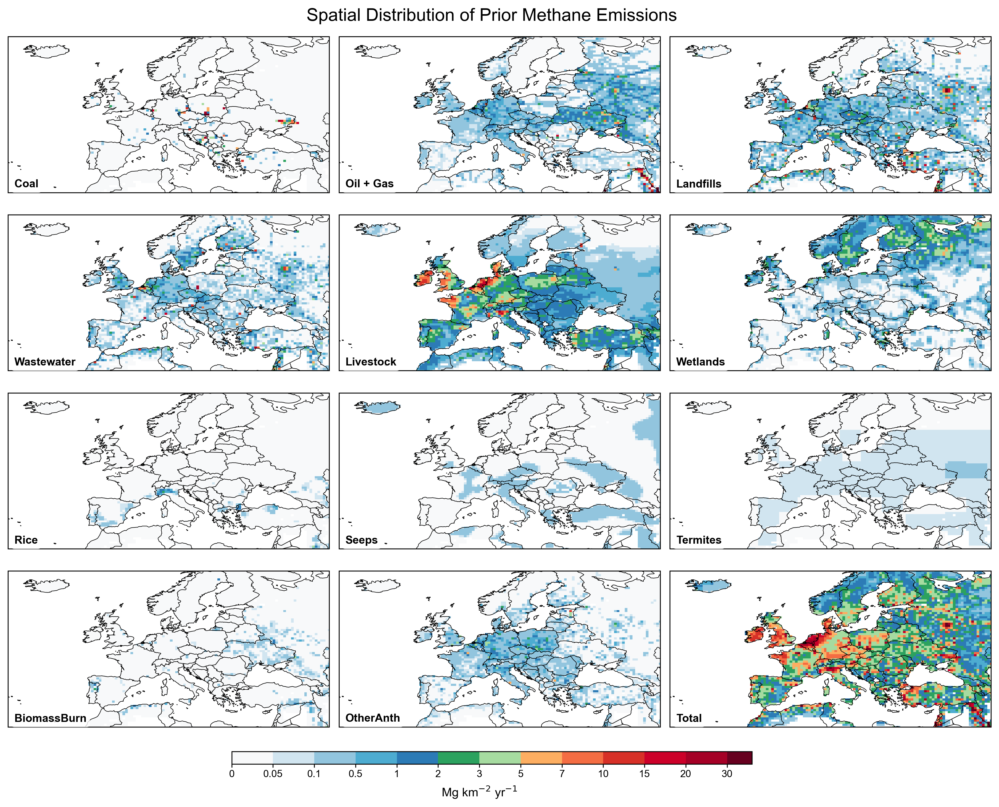

In [4]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm, ListedColormap

# ================================================
YEAR = 2019
HEMCO_PATH = rf"F:\Inv_EU\HEMCO\{YEAR}\HEMCO_diagnostics"
CLUSTER_FILE = r"D:\gc_nested_eu\Clusters_land.nc"
MASK_FILE = r"F:\Inv_EU\mask_valid_high_emission.nc"
SAVE_DIR = r"F:\Inv_EU\SFxEmi_sector_total\prior_sector"

os.makedirs(SAVE_DIR, exist_ok=True)

SAVE_FILE = os.path.join(
    SAVE_DIR,
    f"Prior_Emissions_by_Sector_{YEAR}.png"
)

# ============================================
def compute_prior_emissions(year):

    totals = {}
    variables = []

    for month in range(1, 13):

        time_code = "01010000" if month == 1 else f"{month:02d}010000"

        file = f"{HEMCO_PATH}.{year}{time_code}.nc"

        with xr.open_dataset(file) as ds:

            if month == 1:

                variables = [
                    v for v in ds.data_vars
                    if v.startswith("EmisCH4_")
                ]

                totals = {
                    v: ds[v].sum("time", skipna=True).load()
                    for v in variables
                }

            else:

                for v in variables:
                    totals[v] += ds[v].sum(
                        "time",
                        skipna=True
                    ).load()

        print(f"Loaded: {os.path.basename(file)}")

    return {
        v: totals[v] / 12
        for v in variables
    }


prior = compute_prior_emissions(YEAR)


# ============================================================
# ============================================================

prior["EmisCH4_OilGas"] = (
    prior["EmisCH4_Oil"]
    + prior["EmisCH4_Gas"]
)


# ============================================================
# Total anthropogenic
# ============================================================

prior["EmisCH4_Total"] = (
    prior["EmisCH4_Coal"]
    + prior["EmisCH4_Oil"]
    + prior["EmisCH4_Gas"]
    + prior["EmisCH4_Landfills"]
    + prior["EmisCH4_Wastewater"]
    + prior["EmisCH4_Livestock"]
    + prior["EmisCH4_Rice"]
    + prior["EmisCH4_OtherAnth"]
    +prior["EmisCH4_Seeps"]
    +prior["EmisCH4_Termites"]
     +prior["EmisCH4_BiomassBurn"]
    +prior["EmisCH4_Wetlands"]
)
# ================================================

plot_vars = {

    "Coal":
        "EmisCH4_Coal",

    "Oil + Gas":
        "EmisCH4_OilGas",

    "Landfills":
        "EmisCH4_Landfills",

    "Wastewater":
        "EmisCH4_Wastewater",

    "Livestock":
        "EmisCH4_Livestock",

    "Wetlands":
        "EmisCH4_Wetlands",

    "Rice":
        "EmisCH4_Rice",

    "Seeps":
        "EmisCH4_Seeps",

    "Termites":
        "EmisCH4_Termites",

    "BiomassBurn":
        "EmisCH4_BiomassBurn",

    "OtherAnth":
        "EmisCH4_OtherAnth",

    "Total":
        "EmisCH4_Total",
}

# ===============================================

with xr.open_dataset(CLUSTER_FILE) as ds:

    lon = ds["lon"].load()
    lat = ds["lat"].load()


mask = xr.open_dataarray(
    MASK_FILE
).squeeze().load()


reference = prior["EmisCH4_Coal"].squeeze()


if mask.shape != reference.shape:

    raise ValueError(
        f"掩膜形状{mask.shape}与排放形状{reference.shape}不一致"
    )

# ============================================

boundaries = [
    0, 0.05, 0.1, 0.5, 1, 2, 3,
    5, 7, 10, 15, 20, 30
]


colors = [
    "#f8f9fa",
    "#d1e5f0",
    "#92c5de",
    "#4dacd1",
    "#2c7bb6",
    "#2ca25f",
    "#a6dba0",
    "#fdae61",
    "#f46d43",
    "#d73027",
    "#cc0029",
    "#a50026"
]


cmap = ListedColormap(colors)
cmap.set_over("#67001f")
cmap.set_bad("white", alpha=0)


norm = BoundaryNorm(
    boundaries,
    cmap.N,
    clip=False
)

# ===========================================

fig, axes = plt.subplots(
    4,
    3,
    figsize=(13, 10.5),
    subplot_kw={
        "projection": ccrs.PlateCarree()
    }
)

axes = axes.ravel()


extent = [
    -30 + 3 * 0.625,
    50 - 3 * 0.625,
    30 + 3 * 0.5,
    70 - 3 * 0.5,
]


im = None

# ===========================================

for ax, (title, var) in zip(
        axes,
        plot_vars.items()
):

    emission = (
        prior[var]
        .squeeze()
        * 1e9
        * 31.536
    )


    emission = np.where(
        mask.values == 1,
        emission.values,
        np.nan
    )


    im = ax.pcolormesh(
        lon,
        lat,
        emission,
        cmap=cmap,
        norm=norm,
        shading="auto",
        transform=ccrs.PlateCarree()
    )


    ax.set_extent(
        extent,
        crs=ccrs.PlateCarree()
    )


    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.5
    )


    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.5
    )


    ax.text(
        0.02,
        0.02,
        title,
        transform=ax.transAxes,
        fontsize=10,
        fontweight="bold",
        ha="left",
        va="bottom",
        bbox={
            "facecolor": "white",
            "alpha": 0.8,
            "edgecolor": "none",
            "boxstyle": "round,pad=0.3",
        }
    )

# =========================================

cbar_ax = fig.add_axes(
    [0.25, 0.05, 0.5, 0.015]
)


cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal",
    extend="max",
    extendrect=True,
    spacing="uniform"
)


cbar.set_ticks(boundaries)

cbar.set_ticklabels(
    [f"{v:g}" for v in boundaries]
)


cbar.ax.tick_params(
    axis="x",
    labelsize=9,
    length=3,
    pad=2
)


cbar.set_label(
    r"Mg km$^{-2}$ yr$^{-1}$",
    fontsize=11,
    labelpad=5
)

# ===============================================

fig.suptitle(
    "Spatial Distribution of Prior Methane Emissions",
    fontsize=16,
    y=0.95
)

plt.subplots_adjust(
    left=0.035,
    right=0.98,
    top=0.93,
    bottom=0.08,
    wspace=0.03,
    hspace=-0.01
)

fig.set_dpi(300)           
fig.set_facecolor("white")

plt.show()

In [ ]:
#====Figure 4=====

正在读取数据...


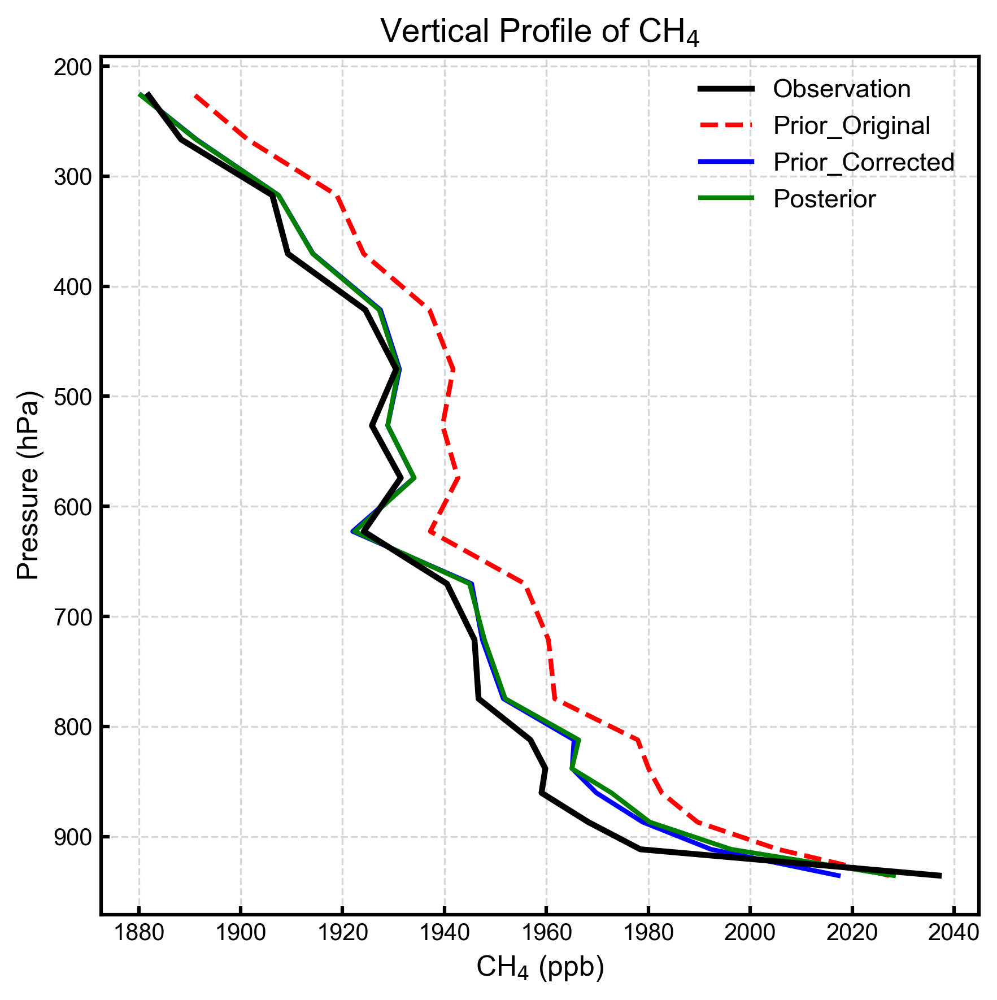

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =================================
def load_and_prepare(pr_file, po_file, pr_file_nbd, pr_file_wbd):
  
    pr_df = pd.read_csv(pr_file)[['LAT', 'LON', 'PRESS', 'OBS', 'TRA_001']].dropna()
    po_df = pd.read_csv(po_file)[['TRA_001']].dropna()
    pr_nbd = pd.read_csv(pr_file_nbd)[['TRA_001']].dropna()
    pr_wbd = pd.read_csv(pr_file_wbd)[['TRA_001']].dropna()

   
    pr_df['TRA_001'] *= 1e9
    po_df['TRA_001'] *= 1e9
    pr_nbd['TRA_001'] *= 1e9
    pr_wbd['TRA_001'] *= 1e9
    tra_orig = pr_df['TRA_001'].values
    correction_nbd = (pr_nbd['TRA_001'].values - tra_orig) * 15  
    correction_wbd = (pr_wbd['TRA_001'].values - tra_orig) * 5   
    total_correction = correction_nbd + correction_wbd

    pr_df['TRA_001_COR'] = tra_orig - total_correction
    pr_df['POSTERIOR'] = po_df['TRA_001'].values - total_correction

    return pr_df

# =================================
print("正在读取数据...")

df_2019 = load_and_prepare(
    r"F:\Inv_EU\IAGOS-CARIBIC_MS_files_collection_20250711\Pr_simu_flight_merged_2019.csv",
    r"F:\Inv_EU\IAGOS-CARIBIC_MS_files_collection_20250711\Po_simu_flight_merged_2019_cornwbd.csv",
    r"F:\Inv_EU\IAGOS-CARIBIC_MS_files_collection_20250711\Pr_simu_flight_merged_nbd2019.csv",
    r"F:\Inv_EU\IAGOS-CARIBIC_MS_files_collection_20250711\Pr_simu_flight_merged_wbd2019.csv"
)

df_2020 = load_and_prepare(
    r"F:\Inv_EU\IAGOS-CARIBIC_MS_files_collection_20250711\Pr_simu_flight_merged_2020.csv",
    r"F:\Inv_EU\IAGOS-CARIBIC_MS_files_collection_20250711\Po_simu_flight_merged_2020_cornwbd.csv",
    r"F:\Inv_EU\IAGOS-CARIBIC_MS_files_collection_20250711\Pr_simu_flight_merged_nbd2020.csv",
    r"F:\Inv_EU\IAGOS-CARIBIC_MS_files_collection_20250711\Pr_simu_flight_merged_wbd2020.csv"
)

combined_df = pd.concat([df_2019, df_2020], ignore_index=True)

# ===========================
bin_edges = list(np.arange(1000, 800, -25)) + list(np.arange(800, 150, -50))
bin_edges = sorted(bin_edges)
combined_df['PRESS_BIN'] = pd.cut(combined_df['PRESS'], bins=bin_edges)

profile = combined_df.groupby('PRESS_BIN', observed=True).agg({
    'OBS': 'mean',
    'TRA_001': 'mean',      
    'TRA_001_COR': 'mean',  
    'POSTERIOR': 'mean',    
    'PRESS': 'mean'
}).dropna()

# ============================
profile_upper = profile[profile['PRESS'] <= 850]

bias_orig = (profile_upper['TRA_001'] - profile_upper['OBS']).mean()
bias_corr = (profile_upper['TRA_001_COR'] - profile_upper['OBS']).mean()
bias_post = (profile_upper['POSTERIOR'] - profile_upper['OBS']).mean()
# ===============================
fig, ax = plt.subplots(figsize=(6, 6))


ax.plot(profile['OBS'], profile['PRESS'], 
        label='Observation', color='black', lw=2.5, zorder=10)


ax.plot(profile['TRA_001'], profile['PRESS'], 
        label='Prior_Original', color='red', linestyle='--', lw=2)

ax.plot(profile['TRA_001_COR'], profile['PRESS'], 
        label='Prior_Corrected', color='blue', lw=2)


ax.plot(profile['POSTERIOR'], profile['PRESS'], 
        label='Posterior', color='green', lw=2)

ax.invert_yaxis()  
ax.set_xlabel('CH$_4$ (ppb)', fontsize=12)
ax.set_ylabel('Pressure (hPa)', fontsize=12)
ax.set_title('Vertical Profile of CH$_4$', fontsize=14)

ax.tick_params(direction='in', width=1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(frameon=False, fontsize=11)
plt.rcParams['figure.dpi'] = 300
plt.tight_layout()
plt.show()

In [ ]:
#===Figure 5a====

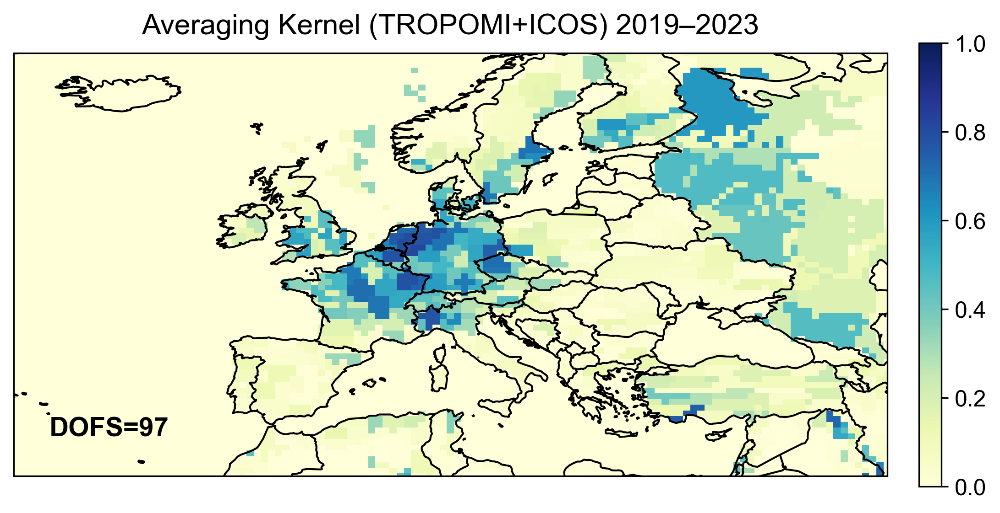

In [8]:
s_hat = pd.read_csv(r'F:\Inv_EU\S_hat\TRO_ICOS_828_tro55_C_icosall_0.5_corBD_optimized_nonmountain\S_hat_2019_2023_vbc_JOINT.csv', header=None)
n_params = 828
# ==================
Sa_first = np.full(n_params, 0.25)
Sa_first[-9:-4] = 0.09  
Sa_first[-4:] = 0.0001     
Sa_yearly = []
for _ in range(5):
    sa_part = np.full(n_params, 0.25)
    sa_part[-9:-4] = 0.09
    sa_part[-4:] = 0.09 
    Sa_yearly.append(sa_part)

Sa_revised = np.concatenate([Sa_first] + Sa_yearly)
Sa_inv = np.diag(1 / Sa_revised)
S_posteri = s_hat
S_x2 = S_posteri@Sa_inv
num_columns = 828*6
I = np.eye(num_columns)
#A1 = I - S_x
A2 = I - S_x2

kernel_s = np.diag(A2)#-----AK diagonal

data_cluster = xr.open_dataset(r'D:/gc_nested_eu/Clusters_land_modified_v8.nc')
cluster = data_cluster['cluster']

lon = data_cluster.coords['lon']
lat = data_cluster.coords['lat']

# to obtain kernel
kernel = np.zeros((len(lat), len(lon)))
#-------in this code we do not need to modify, because if cluster do not include cluster_value, mask will be failed---
for cluster_value in range(1, 824+1):
    mask = (cluster[:,:] == cluster_value)
    kernel[mask] = kernel_s[cluster_value - 1]
kernel_data = xr.DataArray(kernel, coords={'lat': lat, 'lon': lon}, dims=['lat', 'lon'])

# plot kernel sensitivity
fig = plt.figure(figsize=(10, 7),dpi=300)
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

im = kernel_data.plot(ax=ax, transform = ccrs.PlateCarree(),
                        cmap='YlGnBu',vmin=0, vmax=1,add_colorbar=False)
res_lon=0.625
res_lat=0.5
ax.set_extent([-30+3*res_lon, 50-3*res_lon, 30+3*res_lat, 70-3*res_lat], crs=ccrs.PlateCarree())
ax.set_title(label='Averaging Kernel (TROPOMI+ICOS) 2019–2023', fontdict={'fontsize': 15, 'fontweight':200}, pad=10)
ax.set_xlabel('')
ax.set_ylabel('')
cb = plt.colorbar(im, orientation="vertical", pad=0.03, shrink=0.60)
cb.ax.tick_params(labelsize='large')
DOFS = np.sum(kernel_s[0:824])
ax.text(-25, 35, f'DOFS={np.floor(DOFS).astype(int)}', fontsize=14, fontweight='bold')
plt.show()

In [ ]:
#===Figure 5b===

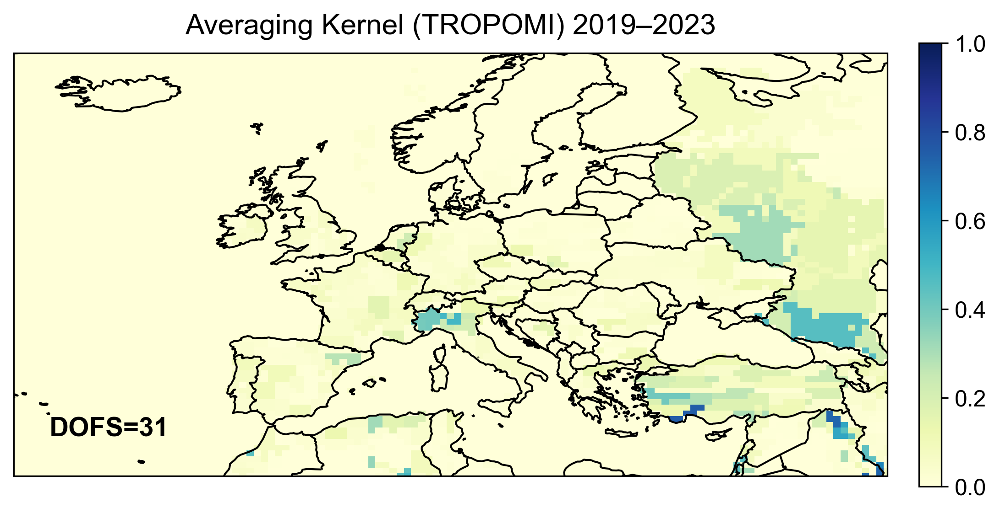

In [9]:
s_hat = pd.read_csv(r'F:\Inv_EU\S_hat\TRO_ICOS_828_tro55_C_icosall_0.5_corBD_optimized\S_hat_2019_2023_vbc_TROPOMI_ONLY.csv', header=None)
n_params = 828
Sa_first = np.full(828, 0.25)
Sa_first[-9:-4] = 0.09  
Sa_first[-4:] = 0.0001    
Sa_yearly = []
for _ in range(5):
    sa_part = np.full(n_params, 0.25)
    sa_part[-9:-4] = 0.09
    sa_part[-4:] = 0.09
    Sa_yearly.append(sa_part)
Sa_revised = np.concatenate([Sa_first] + Sa_yearly)
Sa_inv = np.diag(1 / Sa_revised)

s_hat_subarray = s_hat
S_posteri = s_hat_subarray
S_x2 = S_posteri@Sa_inv
num_columns = 828*6
I = np.eye(num_columns)
#A1 = I - S_x
A2 = I - S_x2

kernel_s = np.diag(A2)#-----AK diagonal

# to obtain kernel
kernel = np.zeros((len(lat), len(lon)))

data_cluster = xr.open_dataset(r'D:/gc_nested_eu/Clusters_land_modified_v8.nc')
cluster = data_cluster['cluster']

lon = data_cluster.coords['lon']
lat = data_cluster.coords['lat']
#-------in this code we do not need to modify, because if cluster do not include cluster_value, mask will be failed---
for cluster_value in range(1, 825):
    mask = (cluster[:,:] == cluster_value)
    kernel[mask] = kernel_s[cluster_value - 1]
kernel_data = xr.DataArray(kernel, coords={'lat': lat, 'lon': lon}, dims=['lat', 'lon'])
fig = plt.figure(figsize=(10, 7),dpi=300)
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

im = kernel_data.plot(ax=ax, transform = ccrs.PlateCarree(),
                        cmap='YlGnBu',vmin=0, vmax=1,add_colorbar=False)
res_lon=0.625
res_lat=0.5
ax.set_extent([-30+3*res_lon, 50-3*res_lon, 30+3*res_lat, 70-3*res_lat], crs=ccrs.PlateCarree())
ax.set_title(label='Averaging Kernel (TROPOMI) 2019–2023', fontdict={'fontsize': 15, 'fontweight':200}, pad=10)
ax.set_xlabel('')
ax.set_ylabel('')
cb = plt.colorbar(im, orientation="vertical", pad=0.03, shrink=0.60)
cb.ax.tick_params(labelsize='large')
DOFS = np.sum(kernel_s[0:824])
ax.text(-25, 35, f'DOFS={np.floor(DOFS).astype(int)}', fontsize=14, fontweight='bold')
plt.show()

In [ ]:
#===Figure 5c=====

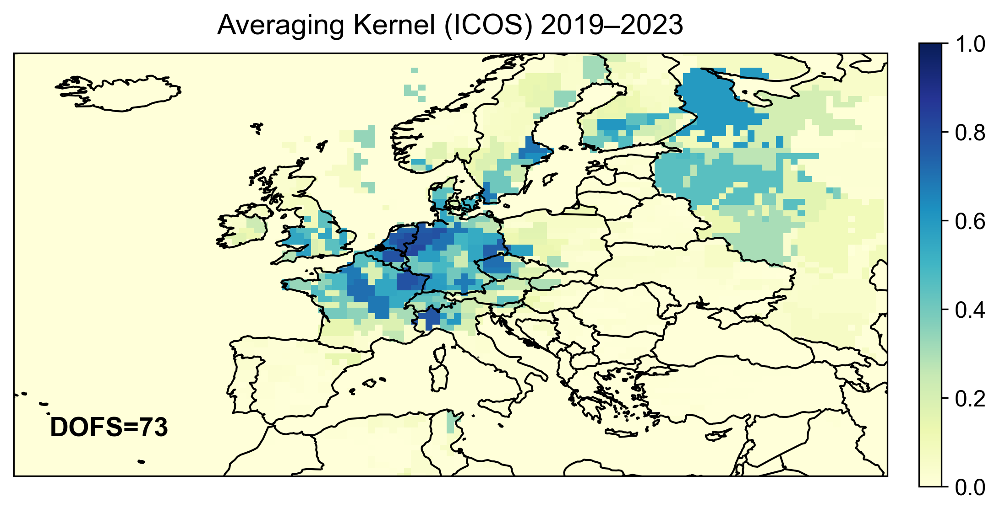

In [10]:
s_hat = pd.read_csv(r'F:\Inv_EU\S_hat\TRO_ICOS_828_tro55_C_icosall_0.5_corBD_optimized_nonmountain\S_hat_2019_2023_vbc_ICOS_ONLY.csv', header=None)
n_params = 828
Sa_first = np.full(828, 0.25)
Sa_first[-9:-4] = 0.09 
Sa_first[-4:] = 0.0001  
Sa_yearly = []
for _ in range(5):
    sa_part = np.full(n_params, 0.25)
    sa_part[-9:-4] = 0.09
    sa_part[-4:] = 0.09 
    Sa_yearly.append(sa_part)
Sa_revised = np.concatenate([Sa_first] + Sa_yearly)
Sa_inv = np.diag(1 / Sa_revised)

s_hat_subarray = s_hat
S_posteri = s_hat_subarray
S_x2 = S_posteri@Sa_inv
num_columns = 828*6
I = np.eye(num_columns)
A2 = I - S_x2
kernel_s = np.diag(A2)#-----AK diagonal

# to obtain kernel
data_cluster = xr.open_dataset(r'D:/gc_nested_eu/Clusters_land_modified_v8.nc')
cluster = data_cluster['cluster']

lon = data_cluster.coords['lon']
lat = data_cluster.coords['lat']

kernel = np.zeros((len(lat), len(lon)))
#-------in this code we do not need to modify, because if cluster do not include cluster_value, mask will be failed---
for cluster_value in range(1, 825):
    mask = (cluster[:,:] == cluster_value)
    kernel[mask] = kernel_s[cluster_value - 1]
kernel_data = xr.DataArray(kernel, coords={'lat': lat, 'lon': lon}, dims=['lat', 'lon'])
fig = plt.figure(figsize=(10, 7),dpi=300)
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

im = kernel_data.plot(ax=ax, transform = ccrs.PlateCarree(),
                        cmap='YlGnBu',vmin=0, vmax=1,add_colorbar=False)
res_lon=0.625
res_lat=0.5
ax.set_extent([-30+3*res_lon, 50-3*res_lon, 30+3*res_lat, 70-3*res_lat], crs=ccrs.PlateCarree())

ax.set_title(label='Averaging Kernel (ICOS) 2019–2023', fontdict={'fontsize': 15, 'fontweight':200}, pad=10)
ax.set_xlabel('')
ax.set_ylabel('')
cb = plt.colorbar(im, orientation="vertical", pad=0.03, shrink=0.60)
cb.ax.tick_params(labelsize='large')
DOFS = np.sum(kernel_s[0:824])
ax.text(-25, 35, f'DOFS={np.floor(DOFS).astype(int)}', fontsize=14, fontweight='bold')
plt.show()


In [ ]:
#====Figure 5d====

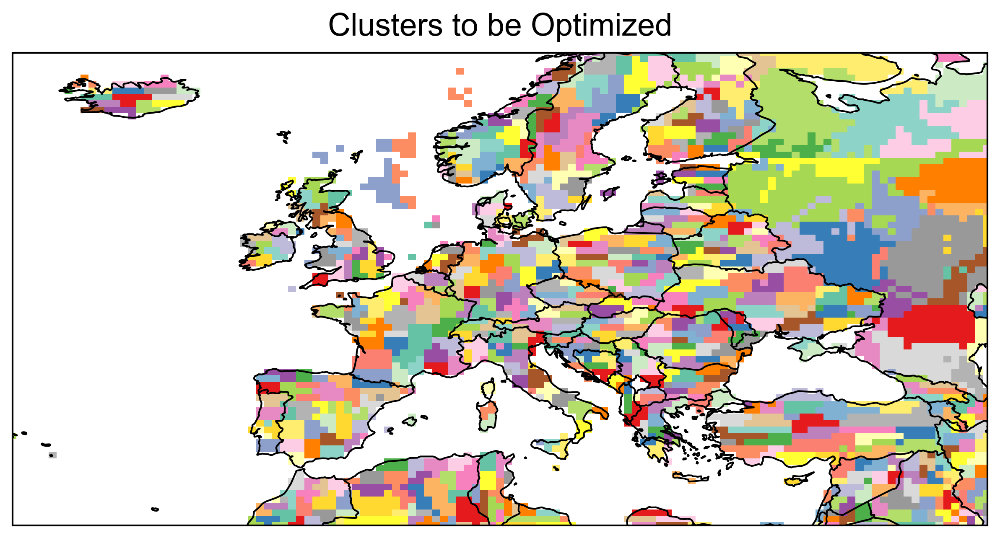

In [7]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import netCDF4 as nc
import matplotlib
matplotlib.rcParams['font.family'] = 'Arial'
%matplotlib inline 
colors_list = (
    plt.cm.Set1.colors
    + plt.cm.Set2.colors
    + plt.cm.Set3.colors
)

num_colors = len(colors_list)

def get_cluster_color(cluster_value):
    if cluster_value == 0:
        return None
    return colors_list[(cluster_value - 1) % num_colors]

ds = nc.Dataset(
    r'D:/gc_nested_eu/Clusters_land_modified_v8.nc'
)

cluster_data = ds.variables['cluster'][:]
lat = ds.variables['lat'][:]
lon = ds.variables['lon'][:]

color_mapped_data = np.empty(
    cluster_data.shape + (3,),
    dtype=np.uint8
)

for i in range(cluster_data.shape[0]):
    for j in range(cluster_data.shape[1]):

        cluster_value = cluster_data[i, j]
        color = get_cluster_color(cluster_value)

        if color is None:
            rgb = np.array([255, 255, 255])
        else:
            rgb = np.array(color) * 255

        color_mapped_data[i, j] = rgb

color_mapped_data_xr = xr.DataArray(
    color_mapped_data,
    coords={
        'lat': lat,
        'lon': lon
    },
    dims=(
        'lat',
        'lon',
        'rgb'
    )
)

fig, ax = plt.subplots(
    figsize=(10, 7),
    subplot_kw={
        'projection': ccrs.PlateCarree()
    },
    dpi=300
)

color_mapped_data_xr.plot.imshow(
    ax=ax,
    x='lon',
    y='lat',
    transform=ccrs.PlateCarree(),
    interpolation='none'
)

ax.add_feature(
    cfeature.COASTLINE
)

ax.add_feature(
    cfeature.BORDERS
)
res_lon = 0.625
res_lat = 0.5

ax.set_extent(
    [
        -30 + 3 * res_lon,
        50 - 3 * res_lon,
        30 + 3 * res_lat,
        70 - 3 * res_lat
    ],
    crs=ccrs.PlateCarree()
)

for spine in ax.spines.values():
    spine.set_linewidth(1)

ax.set_title(
    'Clusters to be Optimized',
    fontsize=18,
    fontweight=200,
    pad=10
)

ax.set_xlabel('')
ax.set_ylabel('')

plt.show()

In [ ]:
#====Figure 6===

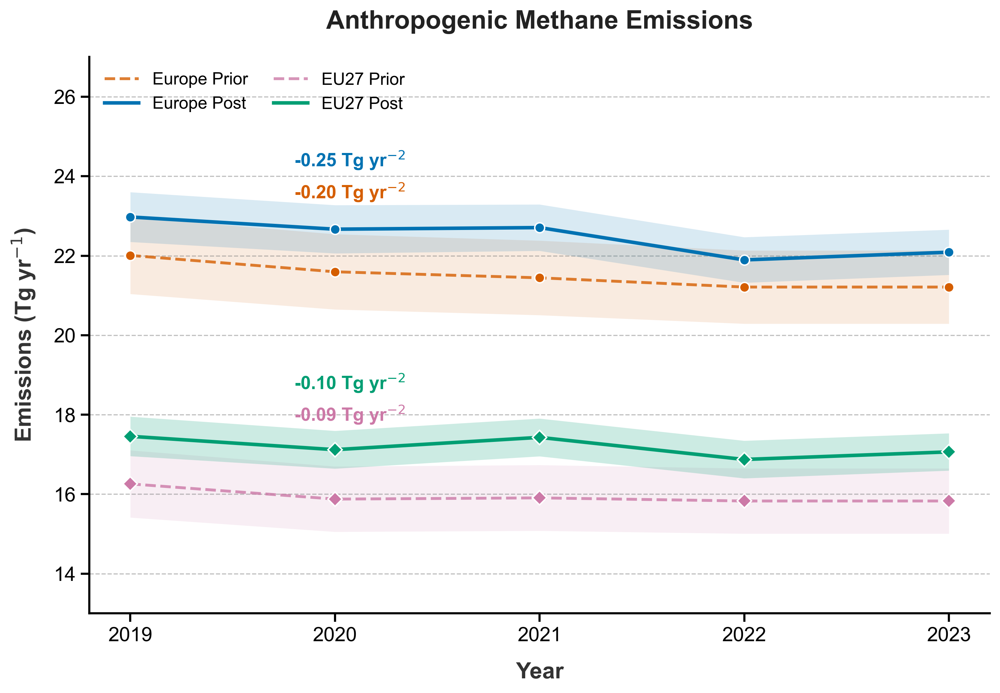

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ==========================================
# ==========================================
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['font.size'] = 14
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# ==========================================
file_path = (
    r'F:\Inv_EU\emi_df'
    r'\TRO_ICOS_828_tro55_C_icosall_0.5_corBD'
    r'\po_pr_emi_both_std_nomountainv3.csv'
)

final_df = pd.read_csv(file_path)

required_std_columns = ['std', 'pr_std']

missing_columns = [
    col for col in required_std_columns
    if col not in final_df.columns
]

if missing_columns:
    raise ValueError(
        f'CSV文件缺少以下不确定度列：{missing_columns}'
    )
eu27_countries = [
    'Austria',
    'Belgium',
    'Bulgaria',
    'Croatia',
    'Cyprus',
    'Czechia',
    'Denmark',
    'Estonia',
    'Finland',
    'France',
    'Germany',
    'Greece',
    'Hungary',
    'Ireland',
    'Italy',
    'Latvia',
    'Lithuania',
    'Luxembourg',
    'Malta',
    'Netherlands',
    'Poland',
    'Portugal',
    'Romania',
    'Slovakia',
    'Slovenia',
    'Spain',
    'Sweden'
]

cols_pr = [
    'pr_Coal',
    'pr_Rice',
    'pr_Landfills',
    'pr_Livestock',
    'pr_Wastewater',
    'pr_Oil',
    'pr_Gas',
    'pr_OtherAnth'
]

cols_po = [
    'po_Coal',
    'po_Rice',
    'po_Landfills',
    'po_Livestock',
    'po_Wastewater',
    'po_Oil',
    'po_Gas',
    'po_OtherAnth'
]

# ==========================================
# 1. Europe All
# ==========================================

prior_eur = (
    final_df.groupby('year')[cols_pr]
    .sum()
    .sum(axis=1)
    / 1e9
)

post_eur = (
    final_df.groupby('year')[cols_po]
    .sum()
    .sum(axis=1)
    / 1e9
)

std_eur = (
    final_df.groupby('year')['std']
    .apply(lambda x: np.sqrt(np.sum(x**2)))
    / 1e9
)

pr_std_eur = (
    final_df.groupby('year')['pr_std']
    .apply(lambda x: np.sqrt(np.sum(x**2)))
    / 1e9
)

# ==========================================
# EU27
# ==========================================

df_eu = final_df[
    final_df['name'].isin(eu27_countries)
].copy()

prior_eu = (
    df_eu.groupby('year')[cols_pr]
    .sum()
    .sum(axis=1)
    / 1e9
)

post_eu = (
    df_eu.groupby('year')[cols_po]
    .sum()
    .sum(axis=1)
    / 1e9
)

std_eu = (
    df_eu.groupby('year')['std']
    .apply(lambda x: np.sqrt(np.sum(x**2)))
    / 1e9
)

pr_std_eu = (
    df_eu.groupby('year')['pr_std']
    .apply(lambda x: np.sqrt(np.sum(x**2)))
    / 1e9
)

# ==========================================
# ==========================================

def get_slope(series):
    return np.polyfit(
        series.index.astype(float),
        series.values,
        1
    )[0]


s_pr_eur = get_slope(prior_eur)
s_po_eur = get_slope(post_eur)
s_pr_eu = get_slope(prior_eu)
s_po_eu = get_slope(post_eu)

# ==========================================
# ==========================================

c_eur_pr = '#D55E00'
c_eur_po = '#0072B2'
c_eu_pr = '#CC79A7'
c_eu_po = '#009E73'

fig, ax = plt.subplots(figsize=(10, 7))

# -------------------------------------------------------
# Group 1: Europe All
# -------------------------------------------------------

# Europe Prior
ax.plot(
    prior_eur.index,
    prior_eur,
    color=c_eur_pr,
    linestyle='--',
    linewidth=2,
    alpha=0.8,
    zorder=3,
    label='Europe Prior'
)

ax.plot(
    prior_eur.index,
    prior_eur,
    marker='o',
    markersize=7,
    color=c_eur_pr,
    markeredgecolor='white',
    markeredgewidth=1,
    linestyle='None',
    zorder=4
)
ax.fill_between(
    prior_eur.index,
    prior_eur - pr_std_eur,
    prior_eur + pr_std_eur,
    color=c_eur_pr,
    alpha=0.12,
    linewidth=0,
    zorder=1
)

# Europe Posterior
ax.plot(
    post_eur.index,
    post_eur,
    color=c_eur_po,
    linestyle='-',
    linewidth=2.5,
    zorder=3,
    label='Europe Post'
)

ax.plot(
    post_eur.index,
    post_eur,
    marker='o',
    markersize=7,
    color=c_eur_po,
    markeredgecolor='white',
    markeredgewidth=1,
    linestyle='None',
    zorder=4
)

# Europe Posterior uncertainty
ax.fill_between(
    post_eur.index,
    post_eur - std_eur,
    post_eur + std_eur,
    color=c_eur_po,
    alpha=0.15,
    linewidth=0,
    zorder=2
)

# -------------------------------------------------------
# Group 2: EU27
# -------------------------------------------------------

# EU27 Prior
ax.plot(
    prior_eu.index,
    prior_eu,
    color=c_eu_pr,
    linestyle='--',
    linewidth=2,
    alpha=0.8,
    zorder=3,
    label='EU27 Prior'
)

ax.plot(
    prior_eu.index,
    prior_eu,
    marker='D',
    markersize=7,
    color=c_eu_pr,
    markeredgecolor='white',
    markeredgewidth=1,
    linestyle='None',
    zorder=4
)
ax.fill_between(
    prior_eu.index,
    prior_eu - pr_std_eu,
    prior_eu + pr_std_eu,
    color=c_eu_pr,
    alpha=0.12,
    linewidth=0,
    zorder=1
)

# EU27 Posterior
ax.plot(
    post_eu.index,
    post_eu,
    color=c_eu_po,
    linestyle='-',
    linewidth=2.5,
    zorder=3,
    label='EU27 Post'
)

ax.plot(
    post_eu.index,
    post_eu,
    marker='D',
    markersize=7,
    color=c_eu_po,
    markeredgecolor='white',
    markeredgewidth=1,
    linestyle='None',
    zorder=4
)

# EU27 Posterior uncertainty
ax.fill_between(
    post_eu.index,
    post_eu - std_eu,
    post_eu + std_eu,
    color=c_eu_po,
    alpha=0.20,
    linewidth=0,
    zorder=2
)

# ==========================================
# ==========================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.4,
    color='gray',
    zorder=0
)

ax.set_ylim(13, 27)

ax.set_xticks(
    prior_eur.index.astype(int)
)

ax.tick_params(
    axis='both',
    direction='out',
    length=6,
    width=1.5,
    colors='black',
    grid_alpha=0.5
)

ax.set_xlabel(
    'Year',
    fontsize=16,
    fontweight='bold',
    labelpad=12,
    color='#333333'
)

ax.set_ylabel(
    r'Emissions (Tg yr$^{-1}$)',
    fontsize=16,
    fontweight='bold',
    labelpad=12,
    color='#333333'
)

ax.set_title(
    'Anthropogenic Methane Emissions',
    fontsize=18,
    fontweight='bold',
    pad=20,
    color='#222222'
)

legend = ax.legend(
    frameon=False,
    fontsize=12,
    loc='upper left',
    ncol=2,
    handlelength=2,
    columnspacing=1.5
)

# ==========================================
# ==========================================

font_style = {
    'fontsize': 13,
    'fontweight': 'bold',
    'ha': 'left',
    'va': 'center'
}

# EU27
ax.text(
    2019.8,
    18,
    f"{s_pr_eu:+.2f} Tg yr$^{{-2}}$",
    color=c_eu_pr,
    **font_style
)

ax.text(
    2019.8,
    18.8,
    f"{s_po_eu:+.2f} Tg yr$^{{-2}}$",
    color=c_eu_po,
    **font_style
)

# Europe
ax.text(
    2019.8,
    23.6,
    f"{s_pr_eur:+.2f} Tg yr$^{{-2}}$",
    color=c_eur_pr,
    **font_style
)

ax.text(
    2019.8,
    24.4,
    f"{s_po_eur:+.2f} Tg yr$^{{-2}}$",
    color=c_eur_po,
    **font_style
)

plt.tight_layout()
plt.show()

In [ ]:
#===Figure 7a===

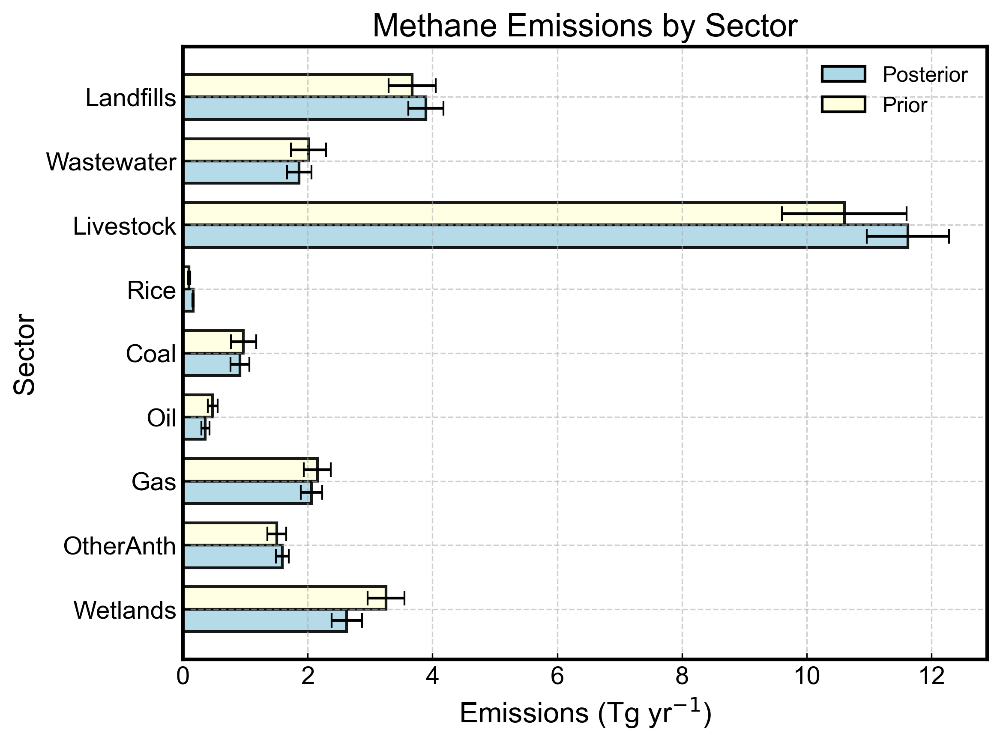

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# -------------------------------
# -------------------------------

file_path = r'F:\Inv_EU\emi_df\TRO_ICOS_828_tro55_C_icosall_0.5_corBD\po_pr_emi_both_std_nomountainv3.csv'
final_df = pd.read_csv(file_path)

df_years = final_df[final_df['year'].between(2019, 2023)].copy()

pr_columns = [
    'pr_Coal', 'pr_Rice', 'pr_Landfills', 'pr_Livestock',
    'pr_Wastewater', 'pr_Oil', 'pr_Gas', 'pr_OtherAnth', 'pr_Wetlands'
#     ,'pr_Seeps','pr_BiomassBurn'
]
po_columns = [col.replace('pr_', 'po_') for col in pr_columns]
pr_values = (
    df_years.groupby('year')[pr_columns]
    .sum()
    .mean()
    .values / 1e9
)

po_values = (
    df_years.groupby('year')[po_columns]
    .sum()
    .mean()
    .values / 1e9
)
sector_names = [col.replace('pr_', '') for col in pr_columns]
df_sectors = pd.DataFrame({
    'Sector': sector_names,
    'Prior': pr_values,
    'Posterior': po_values
})
std_columns = [col.replace('pr_', 'std_') for col in pr_columns]
std_values = (
    df_years.groupby('year')[std_columns]
    .sum()
)

std_values = (
    np.sqrt(
        (std_values**2).sum(axis=0)
    )
    /5
    /1e9
)
df_sectors['Posterior_std'] = std_values

pr_std_columns = [col.replace('pr_', 'pr_std_') for col in pr_columns]
pr_std_values = (
    df_years.groupby('year')[pr_std_columns]
    .sum()
)

pr_std_values = (
    np.sqrt(
        (pr_std_values**2).sum(axis=0)
    )
    /5
    /1e9
)
df_sectors['Posterior_std'] = std_values.values
df_sectors['Prior_std'] = pr_std_values.values
sector_order = [
    'Landfills', 'Wastewater',         # Waste
    'Livestock', 'Rice',               # Agriculture
    'Coal', 'Oil', 'Gas', 'OtherAnth', # Energy
    'Wetlands','Seeps','BiomassBurn'   # Natural
]
df_sectors['Sector'] = pd.Categorical(
    df_sectors['Sector'],
    categories=sector_order,
    ordered=True
)
df_sectors = df_sectors.sort_values(
    'Sector',
    ascending=False
).reset_index(drop=True)

# -------------------------------
# -------------------------------

fig, ax = plt.subplots(figsize=(8, 6))
bar_width = 0.35
index = np.arange(len(df_sectors))

# 后验在下（y = index）
bars2 = ax.barh(
    index,
    df_sectors['Posterior'],
    bar_width,
    color='#ADD8E6',
    edgecolor='black',
    linewidth=1.5,
    alpha=0.9,
    label='Posterior Emission'
)
bars1 = ax.barh(
    index + bar_width,
    df_sectors['Prior'],
    bar_width,
    color='#FFFFE0',
    edgecolor='black',
    linewidth=1.5,
    alpha=0.9,
    label='Prior Emission'
)
ax.errorbar(
    df_sectors['Posterior'],
    index,
    xerr=df_sectors['Posterior_std'],
    fmt='none',
    ecolor='black',
    elinewidth=1.5,
    capsize=4,
    zorder=5
)

ax.errorbar(
    df_sectors['Prior'],
    index + bar_width,
    xerr=df_sectors['Prior_std'],
    fmt='none',
    ecolor='black',
    elinewidth=1.5,
    capsize=4,
    zorder=5
)

ax.set_yticks(index + bar_width / 2)
ax.set_yticklabels(df_sectors['Sector'])
ax.set_xlabel('Emissions (Tg yr$^{-1}$)', fontsize=16)
ax.set_ylabel('Sector', fontsize=16)
ax.set_title('Methane Emissions by Sector', fontsize=18)

custom_lines = [
    Patch(
        facecolor='#ADD8E6',
        edgecolor='black',
        linewidth=1.5,
        label='Posterior'
    ),
    Patch(
        facecolor='#FFFFE0',
        edgecolor='black',
        linewidth=1.5,
        label='Prior'
    )
]

ax.legend(
    handles=custom_lines,
    frameon=False,
    fontsize=12,
    loc='upper right'
)

ax.tick_params(axis='both', labelsize=14, direction='in')
ax.grid(True, linestyle='--', alpha=0.6)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()

In [ ]:
#===Figure 7b===

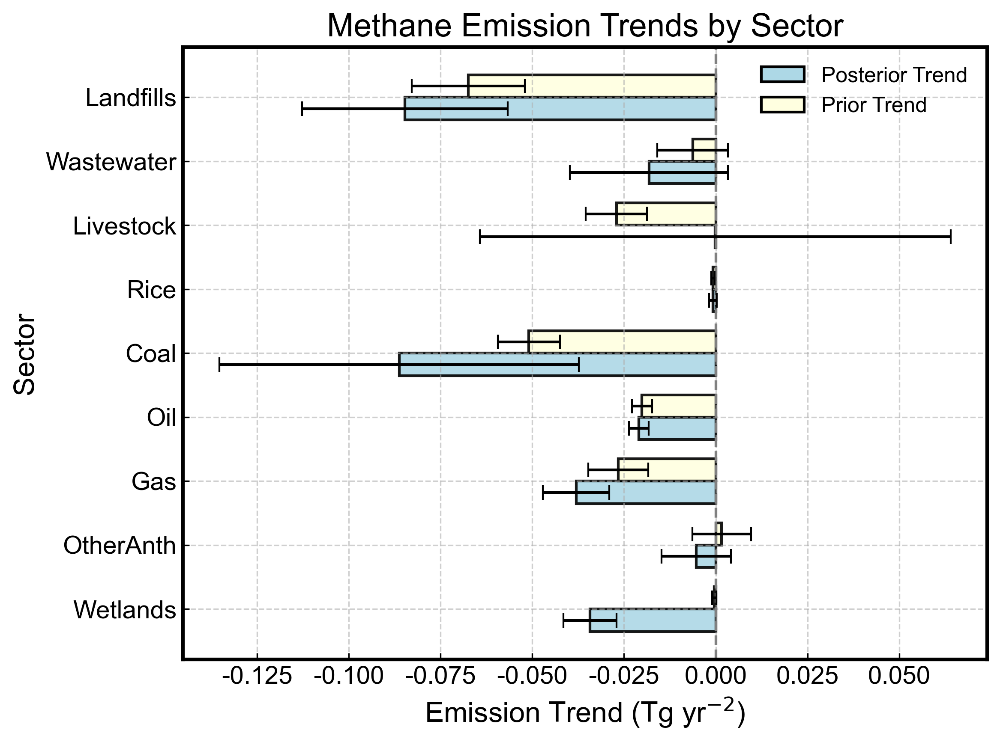

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# -------------------------------
# -------------------------------
file_path = r'F:\Inv_EU\emi_df\TRO_ICOS_828_tro55_C_icosall_0.5_corBD\po_pr_emi_both_std_nomountainv3.csv'
final_df = pd.read_csv(file_path)
df_years = final_df[final_df['year'].between(2019, 2023)].copy()

pr_columns = [
    'pr_Coal', 'pr_Rice', 'pr_Landfills', 'pr_Livestock',
    'pr_Wastewater', 'pr_Oil', 'pr_Gas', 'pr_OtherAnth', 'pr_Wetlands'
]
po_columns = [col.replace('pr_', 'po_') for col in pr_columns]
sector_names = [col.replace('pr_', '') for col in pr_columns]

sector_priors = df_years.groupby('year')[pr_columns].sum() / 1e9
sector_posteriors = df_years.groupby('year')[po_columns].sum() / 1e9
years = sector_priors.index.values.astype(float)

# -------------------------------
# -------------------------------
trend_data = []

for i, sector in enumerate(pr_columns):
    po_col = po_columns[i]
    sector_name = sector.replace('pr_', '')
    coeffs_prior = np.polyfit(
        years,
        sector_priors[sector],
        deg=1
    )
    slope_prior = coeffs_prior[0]
    fitted_prior = np.polyval(coeffs_prior, years)
    residuals_prior = sector_priors[sector] - fitted_prior

    prior_std_err = (
        np.sqrt(
            np.sum(residuals_prior**2) /
            (len(years) - 2)
        ) /
        np.sqrt(
            np.sum((years - np.mean(years))**2)
        )
    )
    coeffs_post = np.polyfit(
        years,
        sector_posteriors[po_col],
        deg=1
    )
    slope_post = coeffs_post[0]
    fitted_post = np.polyval(coeffs_post, years)
    residuals_post = sector_posteriors[po_col] - fitted_post

    posterior_std_err = (
        np.sqrt(
            np.sum(residuals_post**2) /
            (len(years) - 2)
        ) /
        np.sqrt(
            np.sum((years - np.mean(years))**2)
        )
    )

    trend_data.append({
        'Sector': sector_name,
        'Slope_Prior': slope_prior,
        'Slope_Posterior': slope_post,
        'Prior_std': prior_std_err,
        'Posterior_std': posterior_std_err
    })

df_trends = pd.DataFrame(trend_data)

# -------------------------------
# -------------------------------
sector_order = [
    'Landfills', 'Wastewater',             # Waste
    'Livestock', 'Rice',                   # Agriculture
    'Coal', 'Oil', 'Gas', 'OtherAnth',     # Energy
    'Wetlands'                             # Natural
]

df_trends['Sector'] = pd.Categorical(
    df_trends['Sector'],
    categories=sector_order,
    ordered=True
)

df_trends = df_trends.sort_values(
    'Sector',
    ascending=False
).reset_index(drop=True)

# -------------------------------
# -------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
bar_width = 0.35
index = np.arange(len(df_trends))

bars2 = ax.barh(
    index,
    df_trends['Slope_Posterior'],
    bar_width,
    color='#ADD8E6',
    edgecolor='black',
    linewidth=1.5,
    alpha=0.9,
    label='Posterior Trend'
)

bars1 = ax.barh(
    index + bar_width,
    df_trends['Slope_Prior'],
    bar_width,
    color='#FFFFE0',
    edgecolor='black',
    linewidth=1.5,
    alpha=0.9,
    label='Prior Trend'
)

ax.errorbar(
    df_trends['Slope_Posterior'],
    index,
    xerr=df_trends['Posterior_std'],
    fmt='none',
    ecolor='black',
    elinewidth=1.5,
    capsize=4,
    zorder=5
)

ax.errorbar(
    df_trends['Slope_Prior'],
    index + bar_width,
    xerr=df_trends['Prior_std'],
    fmt='none',
    ecolor='black',
    elinewidth=1.5,
    capsize=4,
    zorder=5
)

ax.set_yticks(index + bar_width / 2)
ax.set_yticklabels(df_trends['Sector'])
ax.set_xlabel('Emission Trend (Tg yr$^{-2}$)', fontsize=16)
ax.set_ylabel('Sector', fontsize=16)
ax.set_title(
    'Methane Emission Trends by Sector',
    fontsize=18
)

custom_lines = [
    Patch(
        facecolor='#ADD8E6',
        edgecolor='black',
        linewidth=1.5,
        label='Posterior Trend'
    ),
    Patch(
        facecolor='#FFFFE0',
        edgecolor='black',
        linewidth=1.5,
        label='Prior Trend'
    )
]

ax.legend(
    handles=custom_lines,
    frameon=False,
    fontsize=12,
    loc='upper right'
)

ax.tick_params(axis='both', labelsize=14, direction='in')
ax.axvline(0, color='gray', linestyle='--', linewidth=1.5)
ax.grid(True, linestyle='--', alpha=0.6)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()

In [ ]:
#===Figure 8====

Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201901010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201902010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201903010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201904010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201905010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201906010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201907010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201908010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201909010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201910010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201911010000.nc
Loading: F:\Inv_EU\HEMCO\2019\HEMCO_diagnostics.201912010000.nc
Loading: F:\Inv_EU\HEMCO\2020\HEMCO_diagnostics.202001010000.nc
Loading: F:\Inv_EU\HEMCO\2020\HEMCO_diagnostics.202002010000.nc
Loading: F:\Inv_EU\HEMCO\2020\HEMCO_diagnostics.202003010000.nc
Loading: F:\Inv_EU\HEMCO\2020\HEMCO_diag

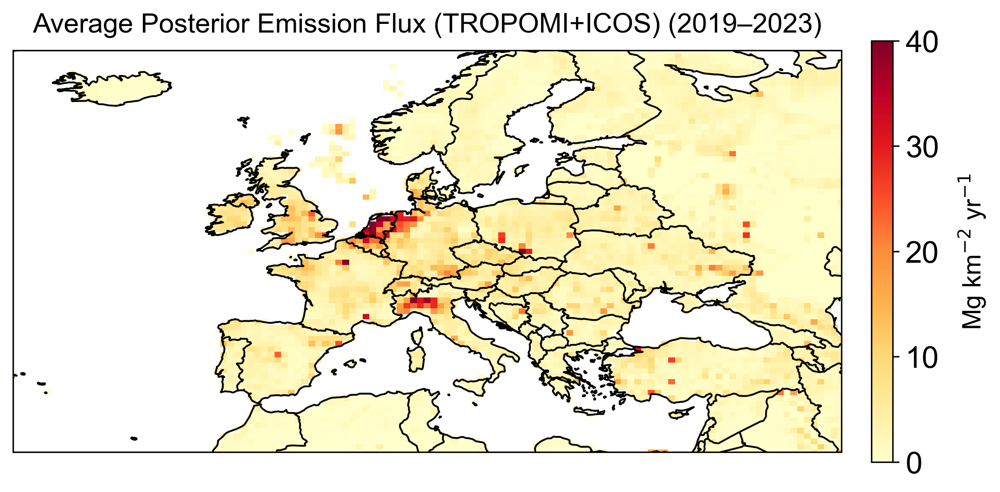

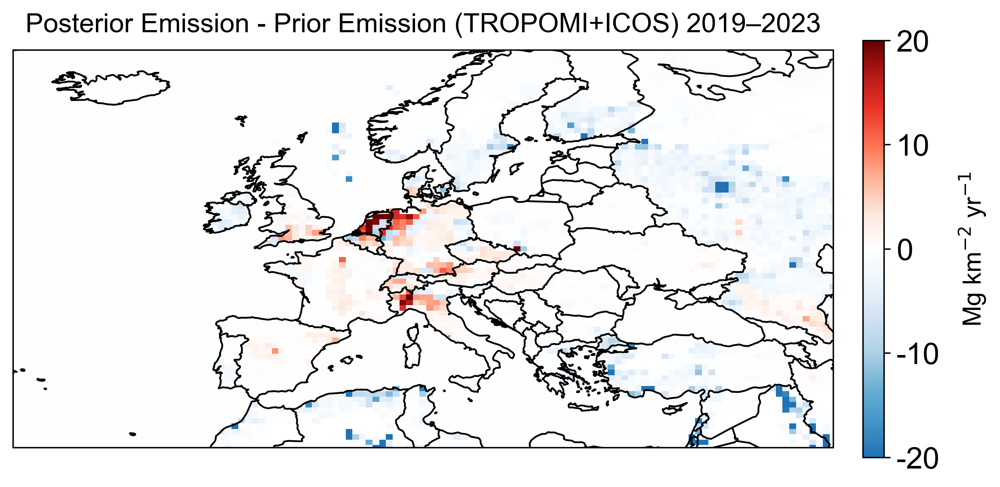

In [14]:
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import (
    LinearSegmentedColormap,
    TwoSlopeNorm
)

# ==========================================================
# 1. Path
# ==========================================================

base_paths = {
    2019: r'F:\Inv_EU\HEMCO\2019',
    2020: r'F:\Inv_EU\HEMCO\2020',
    2021: r'F:\Inv_EU\HEMCO\2021',
    2022: r'F:\Inv_EU\HEMCO\2022',
    2023: r'F:\Inv_EU\HEMCO\2023'
}
var_name_total = 'EmisCH4_Total'
var_name_soil = 'EmisCH4_SoilAbsorb'
# ==========================================================
# 2. Calculate Prior
# ==========================================================

total_sum_array = None
total_months = 0


for year, base_path in base_paths.items():

    for month in range(1,13):

        file_path = (
            fr'{base_path}\HEMCO_diagnostics.'
            f'{year}{month:02d}010000.nc'
        )

        print("Loading:", file_path)


        ds = xr.open_dataset(file_path)


        total_data = ds[var_name_total].sum(dim="time")

        soil_data = ds[var_name_soil].sum(dim="time")


        result_data = total_data - soil_data



        if total_sum_array is None:

            total_sum_array = result_data.values.copy()

        else:

            total_sum_array += result_data.values


        total_months += 1

        ds.close()

prior_average_array = (
    total_sum_array /
    total_months
)

# ==========================================================
# 3. Posterior scaling
# ==========================================================
cluster_ds = xr.open_dataset(
    r'D:\gc_nested_eu\Clusters_land_modified_v8.nc'
)
cluster = cluster_ds['cluster']

lon = cluster_ds['lon']
lat = cluster_ds['lat']

sf = pd.read_csv(
    r'F:\Inv_EU\SF\TRO_ICOS_828_tro55_C_icosall_0.5_corBD_optimized_nonmountain\SF_2019_2023_vbc_JOINT.csv',
    header=None
)
SCF = sf.iloc[:824,0].values

posterior_average_array = (
    prior_average_array.copy()
)

for cluster_value in range(1,825):

    cluster_mask = (
        cluster.values == cluster_value
    )

    posterior_average_array[
        cluster_mask
    ] *= SCF[cluster_value-1]

# ==========================================================
# 4. DataArray
# ==========================================================
prior_average = xr.DataArray(
    prior_average_array,
    coords={
        "lat":lat,
        "lon":lon
    },
    dims=[
        "lat",
        "lon"
    ]
)

posterior_average = xr.DataArray(
    posterior_average_array,
    coords={
        "lat":lat,
        "lon":lon
    },
    dims=[
        "lat",
        "lon"
    ]
)
# ==========================================================
# 5. Unit conversion
# ==========================================================

prior_average = (
    prior_average
    *1e9
    *31.536
)
posterior_average = (
    posterior_average
    *1e9
    *31.536
)

# ==========================================================
# 6. Difference first
# ==========================================================


difference = (
    posterior_average -
    prior_average
)

diff_no_zero = difference.where(
    difference != 0,
    np.nan
)
# ==========================================================
# 7. Apply mask
# ==========================================================


difference = posterior_average - prior_average


diff_no_zero = difference.where(
    difference != 0.0,
    np.nan
)


valid_mask = ~np.isnan(diff_no_zero)


posterior_average = posterior_average.where(
    valid_mask
)

# ==========================================================
# 8. Colormap
# ==========================================================
# --------------------------
# Fig8a
# emission intensity
# yellow-orange-red
# --------------------------
posterior_colors = [

    "#ffffcc",
    "#ffeda0",
    "#fed976",
    "#feb24c",
    "#fd8d3c",
    "#f03b20",
    "#bd0026"

]
posterior_cmap = LinearSegmentedColormap.from_list(
    "posterior_YlOrRd",
    posterior_colors,
    N=256
)
posterior_cmap.set_bad(
    color="white",
    alpha=0
)

# --------------------------
# Fig8b
# anomaly
# blue-white-red
# --------------------------
difference_colors = [
    (0.00, "#2172b4"),
    (0.08, "#4393c6"),
    (0.16, "#69add4"),
    (0.25, "#add1e5"),
    (0.33, "#d0e1f3"),
    (0.42, "#ecf5fc"),

    (0.50, "#ffffff"),

    (0.58, "#fde9de"),
    (0.67, "#fdb398"),
    (0.75, "#fc7353"),
    (0.84, "#e63228"),
    (0.92, "#b31818"),
    (1.00, "#660000")
]
difference_cmap = LinearSegmentedColormap.from_list(
    "custom_blue_white_red",
    difference_colors,
    N=256
)

difference_norm = TwoSlopeNorm(
    vmin=-20,
    vcenter=0,
    vmax=20
)
# ==========================================================
# Map setting function
# ==========================================================
def create_map():


    fig = plt.figure(
        figsize=(10,7),
        dpi=300
    )
    ax = plt.axes(
        projection=ccrs.PlateCarree()
    )
    ax.add_feature(
        cfeature.COASTLINE
    )
    ax.add_feature(
        cfeature.BORDERS
    )
    res_lon = 0.625
    res_lat = 0.5


    ax.set_extent(
        [
            -30+3*res_lon,
            50-3*res_lon,
            30+3*res_lat,
            70-3*res_lat
        ],
        crs=ccrs.PlateCarree()
    )
    return fig, ax

# ==========================================================
# Fig 8a Posterior
# ==========================================================
fig, ax = create_map()

im = (
    posterior_average.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='YlOrRd',
        vmin=0,
        vmax=40,
        add_colorbar=False
    )
)
ax.set_title(
    label='Average Posterior Emission Flux (TROPOMI+ICOS) (2019–2023)',
    fontdict={
        'fontsize':15,
        'fontweight':200
    },
    pad=10
)

ax.set_xlabel('')
ax.set_ylabel('')

cb = plt.colorbar(
    im,
    orientation="vertical",
    pad=0.03,
    shrink=0.60
)

cb.set_label(
    label='Mg km$^{-2}$ yr$^{-1}$',
    size=14,
    labelpad=10
)
cb.ax.tick_params(
    labelsize='large'
)

plt.show()

# ==========================================================
# Fig 8b Difference
# ==========================================================

fig, ax = create_map()


im = (
    difference.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),

        cmap=difference_cmap,

        norm=difference_norm,

        add_colorbar=False
    )
)

ax.set_title(
    label='Posterior Emission - Prior Emission (TROPOMI+ICOS) 2019–2023',
    fontdict={
        'fontsize':15,
        'fontweight':200
    },
    pad=10
)

ax.set_xlabel('')
ax.set_ylabel('')

cb = plt.colorbar(
    im,
    orientation="vertical",
    pad=0.03,
    shrink=0.60
)

cb.set_label(
    label='Mg km$^{-2}$ yr$^{-1}$',
    size=14,
    labelpad=10
)

cb.ax.tick_params(
    labelsize='large'
)

plt.show()

In [ ]:
#===Figure 9=====

wrote D:\codex_output\figure9_2023_comparison\figures\figure9_original_format_2023_reviewer_links_only.png
wrote D:\codex_output\figure9_2023_comparison\figures\figure9_original_format_2023_reviewer_links_only.pdf
wrote D:\codex_output\figure9_2023_comparison\tables\figure9_original_format_2023_reviewer_links_only_values.csv


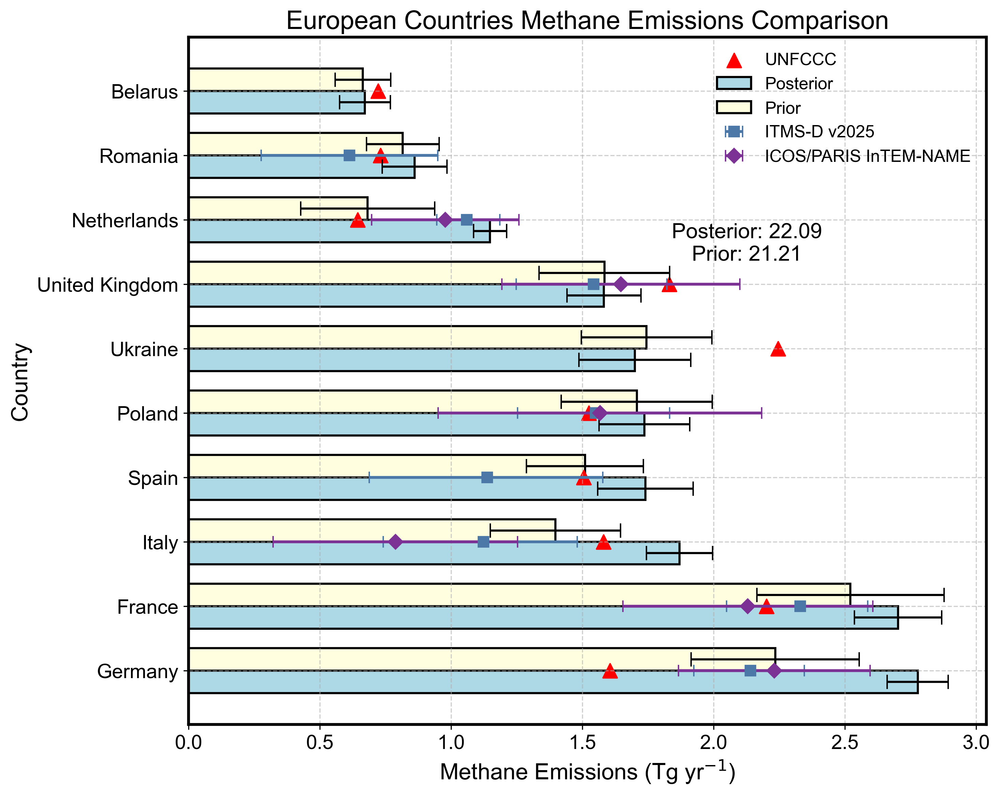

In [15]:
from pathlib import Path
import re
OUT = Path(r"D:\codex_output\figure9_2023_comparison")
FIG_DIR = OUT / "figures"
TABLE_DIR = OUT / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


# This study: 2023 posterior and prior anthropogenic emissions.
file_path = r"F:\Inv_EU\emi_df\TRO_ICOS_828_tro55_C_icosall_0.5_corBD\po_pr_emi_both_std_nomountainv3.csv"
final_df = pd.read_csv(file_path)
df_2023 = final_df[final_df["year"] == 2023].copy()

anthro_sectors = [
    "Coal",
    "Rice",
    "Landfills",
    "Livestock",
    "Wastewater",
    "Oil",
    "Gas",
    "OtherAnth",
]
df_2023["po_anthro"] = sum(df_2023[f"po_{sector}"] for sector in anthro_sectors)
df_2023["pr_anthro"] = sum(df_2023[f"pr_{sector}"] for sector in anthro_sectors)

po_std_columns = [
    f"std_{sector}" for sector in anthro_sectors
]

pr_std_columns = [
    f"pr_std_{sector}" for sector in anthro_sectors
]

df_2023["po_anthro_std"] = np.sqrt(
    df_2023[po_std_columns].pow(2).sum(axis=1)
)

df_2023["pr_anthro_std"] = np.sqrt(
    df_2023[pr_std_columns].pow(2).sum(axis=1)
)

top_10_countries = df_2023.sort_values("po_anthro", ascending=False).head(10).copy()
y_labels = top_10_countries["name"]


# UNFCCC 2023 CRT totals; Poland uses the previous local 2021 fallback if 2023 is missing.
unfccc_2023_path = (
    OUT
    / "unfccc_2026"
    / "tables"
    / "unfccc_2026_crt_ch4_2023_figure9_top10_sector_totals_tg_final.csv"
)
df_unfccc_2023 = pd.read_csv(unfccc_2023_path)
df_unfccc_2023 = df_unfccc_2023[["country", "ch4_total_without_lulucf_tg"]].copy()
df_unfccc_2023.rename(
    columns={"country": "name", "ch4_total_without_lulucf_tg": "UNFCCC_plot_Tg"},
    inplace=True,
)

unfccc_2021_path = (
    r"D:\gc_nested_eu\UNFCCC"
    r"\Time Series - CH₄ total without LULUCF, in kt CO₂ equivalent.xlsx"
)
df_unfccc_2021 = pd.read_excel(unfccc_2021_path, skiprows=2)
df_unfccc_2021.rename(columns={"Last Inventory Year (2021)": "2021"}, inplace=True)
df_unfccc_2021["2021"] = pd.to_numeric(df_unfccc_2021["2021"], errors="coerce")
df_unfccc_2021["UNFCCC_2021_Tg"] = df_unfccc_2021["2021"] / (28 * 1000)
df_unfccc_2021["Party"] = df_unfccc_2021["Party"].replace(
    {
        "United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
        "United States of America": "United States",
    }
)
df_unfccc_2021 = df_unfccc_2021[["Party", "UNFCCC_2021_Tg"]].rename(
    columns={"Party": "name"}
)

top_10_countries = top_10_countries.merge(df_unfccc_2023, on="name", how="left")
top_10_countries = top_10_countries.merge(df_unfccc_2021, on="name", how="left")
mask_poland = top_10_countries["name"].eq("Poland") & top_10_countries[
    "UNFCCC_plot_Tg"
].isna()
top_10_countries.loc[mask_poland, "UNFCCC_plot_Tg"] = top_10_countries.loc[
    mask_poland, "UNFCCC_2021_Tg"
]

# ITMS-D v2025 / reviewer Zenodo link: 2023 non-natural posterior country totals.
itms_path = (
    OUT
    / "zenodo_itms_v2025"
    / "tables"
    / "itms_d_v2025_zenodo_ch4_2023_figure9_top10_country_totals_tg.csv"
)
df_itms = pd.read_csv(itms_path)
df_itms.rename(columns={"country": "name"}, inplace=True)
top_10_countries = top_10_countries.merge(
    df_itms[
        [
            "name",
            "itms_non_n_posterior_tg",
            "itms_non_n_posterior_p025_tg",
            "itms_non_n_posterior_p975_tg",
        ]
    ],
    on="name",
    how="left",
)

# ICOS/PARIS reviewer link: InTEM-NAME 2023 country totals.
icos_path = (
    OUT
    / "icos_paris_gr1q_6sk4"
    / "tables"
    / "icos_paris_intem_name_ch4_2023_top10_country_totals_tg.csv"
)
df_icos = pd.read_csv(icos_path)
df_icos.rename(columns={"country": "name"}, inplace=True)
top_10_countries = top_10_countries.merge(
    df_icos[
        [
            "name",
            "posterior_Tg_CH4_yr",
            "posterior_p159_Tg_CH4_yr",
            "posterior_p841_Tg_CH4_yr",
            "available_as_exact_country",
            "explicit_low_uncertainty_country_in_collection_description",
        ]
    ].rename(
        columns={
            "posterior_Tg_CH4_yr": "icos_paris_intem_name_posterior_tg",
            "posterior_p159_Tg_CH4_yr": "icos_paris_intem_name_p159_tg",
            "posterior_p841_Tg_CH4_yr": "icos_paris_intem_name_p841_tg",
            "available_as_exact_country": "icos_available_as_exact_country",
            "explicit_low_uncertainty_country_in_collection_description": (
                "icos_explicit_low_uncertainty_country"
            ),
        }
    ),
    on="name",
    how="left",
)


fig, ax = plt.subplots(figsize=(10, 8))
bar_width = 0.35
index = np.arange(len(top_10_countries))

ax.barh(
    index,
    top_10_countries["po_anthro"] * 1e-9,
    bar_width,
    label="Posterior",
    color="#ADD8E6",
    edgecolor="black",
    linewidth=1.5,
    xerr=top_10_countries["std"] * 1e-9,
    capsize=5,
)

ax.barh(
    index + bar_width,
    top_10_countries["pr_anthro"] * 1e-9,
    bar_width,
    label="Prior",
    color="#FFFFE0",
    edgecolor="black",
    linewidth=1.5,
    xerr=top_10_countries["pr_std"] * 1e-9,
    capsize=5,
)
ax.scatter(
    top_10_countries["UNFCCC_plot_Tg"],
    index + bar_width / 2,
    color="red",
    marker="^",
    s=100,
    label="UNFCCC",
)

soft_blue = "#4C78A8"
for i, row in top_10_countries.iterrows():
    if pd.notna(row["itms_non_n_posterior_tg"]):
        if pd.notna(row["itms_non_n_posterior_p025_tg"]) and pd.notna(
            row["itms_non_n_posterior_p975_tg"]
        ):
            xerr = [
                [row["itms_non_n_posterior_tg"] - row["itms_non_n_posterior_p025_tg"]],
                [row["itms_non_n_posterior_p975_tg"] - row["itms_non_n_posterior_tg"]],
            ]
        else:
            xerr = None
        ax.errorbar(
            x=row["itms_non_n_posterior_tg"],
            y=i + bar_width / 2,
            xerr=xerr,
            fmt="s",
            color=soft_blue,
            ecolor=soft_blue,
            elinewidth=2,
            capsize=4,
            markersize=7,
            label="ITMS-D v2025" if i == 0 else "",
        )

soft_purple = "#7B3294"
icos_label_used = False
for i, row in top_10_countries.iterrows():
    if row.get("icos_available_as_exact_country") != "Yes":
        continue
    if pd.notna(row["icos_paris_intem_name_posterior_tg"]):
        if pd.notna(row["icos_paris_intem_name_p159_tg"]) and pd.notna(
            row["icos_paris_intem_name_p841_tg"]
        ):
            xerr = [
                [
                    row["icos_paris_intem_name_posterior_tg"]
                    - row["icos_paris_intem_name_p159_tg"]
                ],
                [
                    row["icos_paris_intem_name_p841_tg"]
                    - row["icos_paris_intem_name_posterior_tg"]
                ],
            ]
        else:
            xerr = None
        ax.errorbar(
            x=row["icos_paris_intem_name_posterior_tg"],
            y=i + bar_width / 2,
            xerr=xerr,
            fmt="D",
            color=soft_purple,
            ecolor=soft_purple,
            elinewidth=2,
            capsize=4,
            markersize=7,
            label="ICOS/PARIS InTEM-NAME" if not icos_label_used else "",
        )
        icos_label_used = True

ax.set_yticks(index + bar_width / 2)
ax.set_yticklabels(y_labels)
ax.set_xlabel("Methane Emissions (Tg yr$^{-1}$)", fontsize=16)
ax.set_ylabel("Country", fontsize=16)
ax.set_title("European Countries Methane Emissions Comparison", fontsize=18)

handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), frameon=False, fontsize=12, loc="best")

ax.tick_params(axis="both", labelsize=14)
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(2)
ax.grid(True, linestyle="--", alpha=0.6, zorder=0)
plt.tight_layout()

total_po = df_2023["po_anthro"].sum() / 1e9
total_pr = df_2023["pr_anthro"].sum() / 1e9
total_text = f"Posterior: {total_po:.2f}\nPrior: {total_pr:.2f}"
ax.text(0.7, 0.7, total_text, ha="center", va="center", transform=ax.transAxes, fontsize=15)

base = "figure9_original_format_2023_reviewer_links_only"
top_10_countries.to_csv(TABLE_DIR / f"{base}_values.csv", index=False, encoding="utf-8-sig")
top_10_countries.to_excel(TABLE_DIR / f"{base}_values.xlsx", index=False)
fig.savefig(FIG_DIR / f"{base}.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / f"{base}.pdf", bbox_inches="tight")

print("wrote", FIG_DIR / f"{base}.png")
print("wrote", FIG_DIR / f"{base}.pdf")
print("wrote", TABLE_DIR / f"{base}_values.csv")


In [ ]:
#===Figure 10====

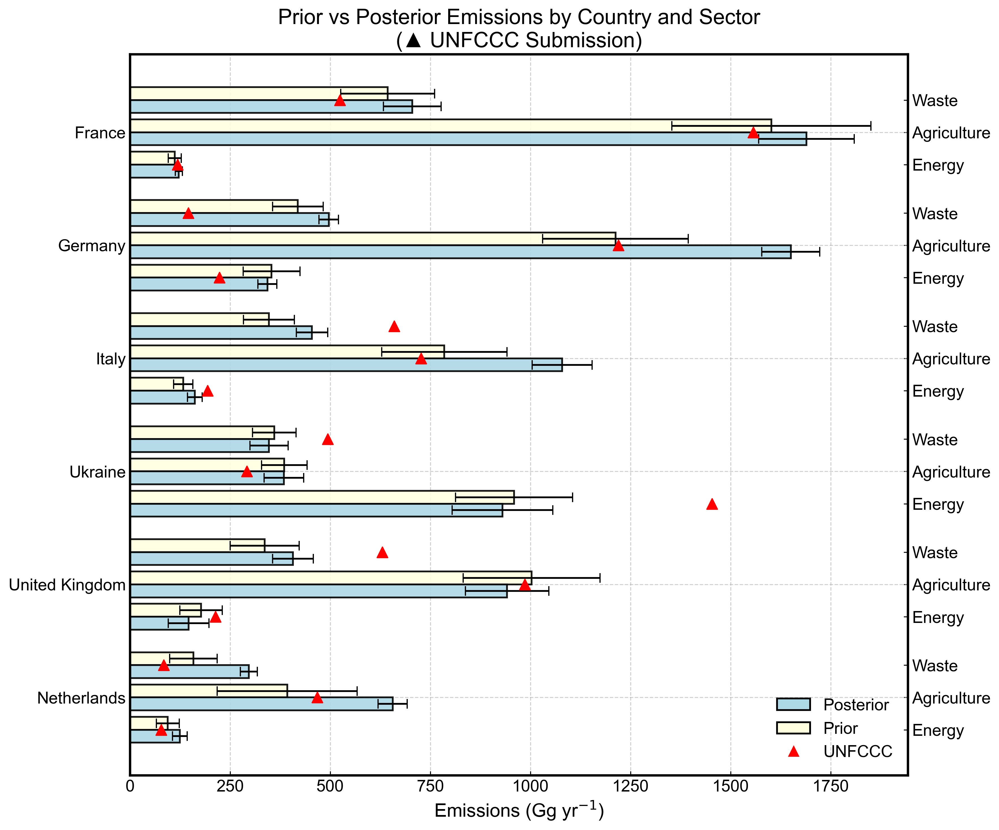

In [17]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ============================================================
# 1. Paths
# ============================================================
# Corrected 2019-2023 inversion output
EMISSION_FILE = Path(
    r"F:\Inv_EU\emi_df"
    r"\TRO_ICOS_828_tro55_C_icosall_0.5_corBD"
    r"\po_pr_emi_both_std_nomountainv3.csv"
)
# UNFCCC 2023 sector totals
UNFCCC_FILE = Path(
    r"D:\codex_output\figure9_2023_comparison"
    r"\unfccc_2026\tables"
    r"\unfccc_2026_crt_ch4_2023_figure9_top10_sector_totals_tg_final.csv"
)

# ============================================================
# 2. Configuration
# ============================================================
YEAR = 2023
SECTORS = [
    "Waste",
    "Agriculture",
    "Energy",
]
# Order used in final figure
COUNTRIES = [
    "France",
    "Germany",
    "Italy",
    "Ukraine",
    "United Kingdom",
    "Netherlands",
]
# Component sectors used ONLY for emission values.
#
# Emissions are additive.
# Uncertainties are NOT calculated from these components.
SECTOR_MEMBERS = {
    "Waste": [
        "Landfills",
        "Wastewater",
    ],
    "Agriculture": [
        "Livestock",
        "Rice",
    ],
    "Energy": [
        "Coal",
        "Oil",
        "Gas",
    ],
}
SECTOR_TO_UNFCCC_COLUMN = {
    "Waste":
        "ch4_waste_tg",
    "Agriculture":
        "ch4_agriculture_tg",
    "Energy":
        "ch4_energy_tg",
}

# ============================================================
# 3. Read data
# ============================================================
final_df = pd.read_csv(
    EMISSION_FILE
)
unfccc_df = pd.read_csv(
    UNFCCC_FILE
)

# ============================================================
# 4. Required-column check
# ============================================================
required_columns = [
    "name",
    "year",
    # emission components
    "po_Landfills",
    "po_Wastewater",
    "po_Livestock",
    "po_Rice",
    "po_Coal",
    "po_Oil",
    "po_Gas",
    "pr_Landfills",
    "pr_Wastewater",
    "pr_Livestock",
    "pr_Rice",
    "pr_Coal",
    "pr_Oil",
    "pr_Gas",
    # correctly propagated aggregate uncertainties
    "std_Waste",
    "pr_std_Waste",
    "std_Agriculture",
    "pr_std_Agriculture",
    "std_Energy",
    "pr_std_Energy",
]
missing_columns = [
    col
    for col in required_columns
    if col not in final_df.columns
]
if missing_columns:
    raise RuntimeError(
        "Missing required columns:\n"
        + "\n".join(
            missing_columns
        )
    )

# ============================================================
# 5. Check country-year uniqueness
# ============================================================
duplicate_mask = (
    final_df
    .duplicated(
        subset=[
            "name",
            "year",
        ],
        keep=False,
    )
)
if duplicate_mask.any():
    duplicates = (
        final_df.loc[
            duplicate_mask,
            [
                "name",
                "year",
            ],
        ]
        .sort_values(
            [
                "year",
                "name",
            ]
        )
    )
    raise RuntimeError(
        "Duplicate country-year rows found."
    )

# ============================================================
# 6. Select 2023
# ============================================================
df_year = (
    final_df.loc[
        final_df["year"].eq(
            YEAR
        )
    ]
    .copy()
)

# ============================================================
# 7. Functions
# ============================================================

def get_emissions(
    row,
    sector,
):
    """
    Aggregate prior/posterior emission values.
    Emissions are additive.
    Original output -> Gg yr-1 using / 1e6.
    """
    members = (
        SECTOR_MEMBERS[
            sector
        ]
    )
    posterior = sum(
        float(
            row[
                f"po_{member}"
            ]
        )
        for member in members
    ) / 1e6
    prior = sum(
        float(
            row[
                f"pr_{member}"
            ]
        )
        for member in members
    ) / 1e6
    return (
        posterior,
        prior,
    )

def get_uncertainties(
    row,
    sector,
):
    """
    Read the aggregate-sector uncertainty directly from
    the corrected covariance propagation.
    IMPORTANT:
    Do NOT reconstruct uncertainty from individual-sector std.
    """
    posterior_std = (
        float(
            row[
                f"std_{sector}"
            ]
        )
        / 1e6
    )
    prior_std = (
        float(
            row[
                f"pr_std_{sector}"
            ]
        )
        / 1e6
    )
    return (
        posterior_std,
        prior_std,
    )

def get_unfccc(
    country,
    sector,
):
    """
    UNFCCC CSV unit:
        Tg yr-1
    Figure unit:
        Gg yr-1
    1 Tg = 1000 Gg
    """
    rows = (
        unfccc_df.loc[
            unfccc_df[
                "country"
            ].eq(country)
        ]
    )
    if len(rows) != 1:
        raise RuntimeError(
            f"Expected one UNFCCC row "
            f"for {country}; "
            f"found {len(rows)}."
        )
    column = (
        SECTOR_TO_UNFCCC_COLUMN[
            sector
        ]
    )
    value_tg = pd.to_numeric(
        rows[column],
        errors="coerce",
    ).iloc[0]
    if pd.isna(
        value_tg
    ):
        raise RuntimeError(
            f"Missing UNFCCC value: "
            f"{country}, {sector}"
        )
    return (
        float(value_tg)
        * 1000.0
    )

# ============================================================
# 8. Build Figure-10 dataframe
# ============================================================
records = []
for country in COUNTRIES:
    rows = (
        df_year.loc[
            df_year[
                "name"
            ].eq(country)
        ]
    )
    if len(rows) != 1:
        raise RuntimeError(
            f"Expected exactly one "
            f"{YEAR} row for "
            f"{country}; "
            f"found {len(rows)}."
        )
    row = (
        rows.iloc[0]
    )
    for sector in SECTORS:
        posterior, prior = (
            get_emissions(
                row,
                sector,
            )
        )
        (
            posterior_std,
            prior_std,
        ) = get_uncertainties(
            row,
            sector,
        )
        # --------------------------------------------
        # Final safety check
        # --------------------------------------------
        if (
            posterior_std
            > prior_std + 1e-8
        ):
            raise RuntimeError(
                f"{YEAR} "
                f"{country} "
                f"{sector}: "
                f"posterior std "
                f"{posterior_std:.6f} "
                f"> prior std "
                f"{prior_std:.6f}"
            )
        records.append(
            {
                "Country":
                    country,
                "Sector":
                    sector,
                "Prior":
                    prior,
                "Posterior":
                    posterior,
                "UNFCCC":
                    get_unfccc(
                        country,
                        sector,
                    ),
                "Prior_std":
                    prior_std,
                "Posterior_std":
                    posterior_std,
            }
        )
results_df = pd.DataFrame(
    records
)

# ============================================================
# 9. Print exact values used in figure
# ============================================================

# ============================================================
# 10. Plot configuration
# ============================================================
plt.rcParams[
    "figure.dpi"
] = 300
plt.rcParams[
    "savefig.dpi"
] = 300
fig, ax = plt.subplots(
    figsize=(
        12,
        10,
    )
)
bar_width = 0.4
gap_between_groups = 0.5
opacity = 0.9
n_countries = len(
    COUNTRIES
)
n_sectors = len(
    SECTORS
)

# ============================================================
# 11. Y positions
# ============================================================
y_positions = []
y_labels = []
for i, country in enumerate(
    COUNTRIES
):
    for j, sector in enumerate(
        SECTORS
    ):
        y_pos = (
            i
            * (
                n_sectors
                + gap_between_groups
            )
            + j
        )
        y_positions.append(
            y_pos
        )
        y_labels.append(
            sector
        )
country_tick_positions = [
    i
    * (
        n_sectors
        + gap_between_groups
    )
    + (
        n_sectors - 1
    ) / 2
    for i in range(
        n_countries
    )
]
ax.set_yticks(
    country_tick_positions
)
ax.set_yticklabels(
    COUNTRIES,
    fontsize=16,
)

# ============================================================
# 12. Draw bars / error bars / UNFCCC
# ============================================================
for i, country in enumerate(
    COUNTRIES
):
    for j, sector in enumerate(
        SECTORS
    ):
        idx = (
            results_df[
                "Country"
            ].eq(country)
            &
            results_df[
                "Sector"
            ].eq(sector)
        )
        row = (
            results_df
            .loc[idx]
            .iloc[0]
        )
        x_prior = (
            row["Prior"]
        )
        x_posterior = (
            row["Posterior"]
        )
        x_unfccc = (
            row["UNFCCC"]
        )
        prior_std = (
            row["Prior_std"]
        )
        posterior_std = (
            row[
                "Posterior_std"
            ]
        )
        y_pos = (
            i
            * (
                n_sectors
                + gap_between_groups
            )
            + j
        )
        # ----------------------------------------------------
        # Prior bar
        # ----------------------------------------------------
        ax.barh(
            y_pos
            - bar_width / 2,
            x_prior,
            bar_width,
            color="#FFFFE0",
            edgecolor="black",
            alpha=opacity,
            linewidth=1.5,
            zorder=2,
        )
        # Prior uncertainty
        ax.errorbar(
            x_prior,
            y_pos
            - bar_width / 2,
            xerr=prior_std,
            fmt="none",
            ecolor="black",
            elinewidth=1.5,
            capsize=4,
            zorder=5,
        )
        # ----------------------------------------------------
        # Posterior bar
        # ----------------------------------------------------
        ax.barh(
            y_pos
            + bar_width / 2,
            x_posterior,
            bar_width,
            color="#ADD8E6",
            edgecolor="black",
            alpha=opacity,
            linewidth=1.5,
            zorder=2,
        )
        # Posterior uncertainty
        ax.errorbar(
            x_posterior,
            y_pos
            + bar_width / 2,
            xerr=posterior_std,
            fmt="none",
            ecolor="black",
            elinewidth=1.5,
            capsize=4,
            zorder=5,
        )
        # ----------------------------------------------------
        # UNFCCC
        # ----------------------------------------------------
        ax.scatter(
            x_unfccc,
            y_pos,
            color="red",
            marker="^",
            s=80,
            zorder=6,
        )

# ============================================================
# 13. Ukraine Energy special annotation
# ============================================================
x_max = (
    ax.get_xlim()[1]
)
ukraine_energy = (
    results_df.loc[
        results_df[
            "Country"
        ].eq("Ukraine")
        &
        results_df[
            "Sector"
        ].eq("Energy")
    ]
)
unfccc_value = (
    ukraine_energy[
        "UNFCCC"
    ].iloc[0]
)
ukraine_i = (
    COUNTRIES.index(
        "Ukraine"
    )
)
energy_j = (
    SECTORS.index(
        "Energy"
    )
)
y_ukr_energy = (
    ukraine_i
    * (
        n_sectors
        + gap_between_groups
    )
    + energy_j
)
if (
    unfccc_value
    > x_max
):
    x_annotation = (
        x_max
        * 0.99
    )
    ax.scatter(
        x_annotation,
        y_ukr_energy,
        color="red",
        marker="^",
        s=80,
        zorder=10,
    )
    ax.text(
        x_annotation
        + 0.01 * x_max,
        y_ukr_energy,
        f"{unfccc_value:.1f}",
        va="center",
        fontsize=14,
        color="black",
    )
    ax.set_xlim(
        ax.get_xlim()[0],
        x_annotation
        + 0.10 * x_max,
    )

# ============================================================
# 14. Right-side sector labels
# ============================================================
sec_ax = (
    ax.secondary_yaxis(
        "right"
    )
)
sec_ax.set_yticks(
    y_positions
)
sec_ax.set_yticklabels(
    y_labels,
    fontsize=14,
)
sec_ax.tick_params(
    axis="y",
    direction="in",
    labelsize=14,
)

# ============================================================
# 15. Axes
# ============================================================
ax.set_xlabel(
    "Emissions (Gg yr$^{-1}$)",
    fontsize=16,
)
ax.set_ylabel(
    ""
)
ax.set_title(
    "Prior vs Posterior Emissions by Country and Sector\n"
    "(▲ UNFCCC Submission)",
    fontsize=18,
)
ax.grid(
    True,
    linestyle="--",
    alpha=0.6,
    zorder=0,
)
ax.invert_yaxis()
ax.tick_params(
    axis="both",
    which="major",
    labelsize=14,
    direction="in",
)
for spine in (
    ax.spines.values()
):
    spine.set_edgecolor(
        "black"
    )
    spine.set_linewidth(
        2
    )

# ============================================================
# 16. Legend
# ============================================================
custom_lines = [
    Patch(
        facecolor="#ADD8E6",
        edgecolor="black",
        linewidth=1.5,
        label="Posterior",
    ),
    Patch(
        facecolor="#FFFFE0",
        edgecolor="black",
        linewidth=1.5,
        label="Prior",
    ),
    Line2D(
        [0],
        [0],
        color="red",
        marker="^",
        linestyle="",
        markersize=8,
        label="UNFCCC",
    ),
]
ax.legend(
    handles=custom_lines,
    loc="lower right",
    frameon=False,
    fontsize=14,
)

plt.tight_layout()
plt.show()

In [ ]:
#=====Figure 11===

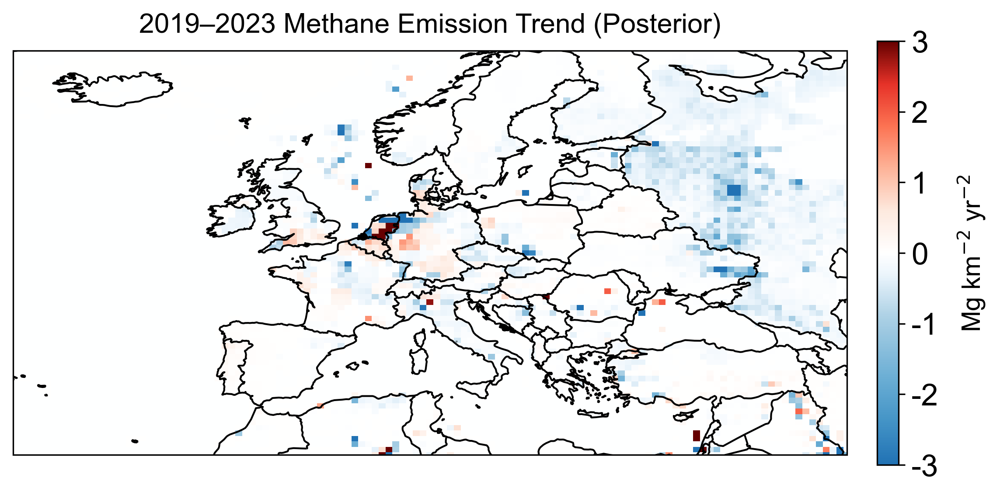

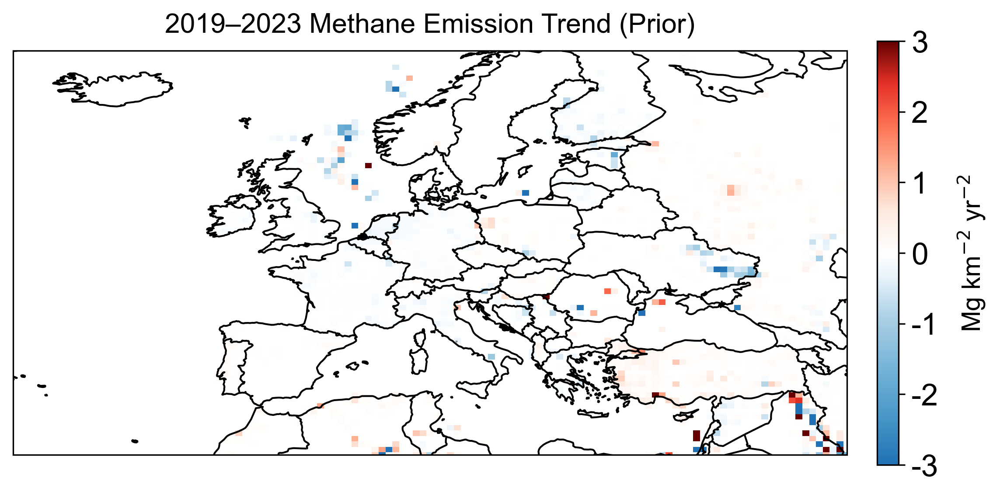

In [18]:
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from scipy.stats import linregress
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm


# ==========================================================
# 1. Scaling factor
# ==========================================================

sf = pd.read_csv(
    r'F:\Inv_EU\SF\TRO_ICOS_828_tro55_C_icosall_0.5_corBD_optimized_nonmountain\SF_2019_2023_vbc_JOINT.csv',
    header=None
)


def get_year_diff_block(sf, year_index, length=824):
    start = year_index * 828
    return sf[start:start + length].values.copy()


SCF_average = get_year_diff_block(sf, 0)

SCF_2019_diff = get_year_diff_block(sf, 1)
SCF_2020_diff = get_year_diff_block(sf, 2)
SCF_2021_diff = get_year_diff_block(sf, 3)
SCF_2022_diff = get_year_diff_block(sf, 4)
SCF_2023_diff = get_year_diff_block(sf, 5)

SCF_2019 = SCF_average + SCF_2019_diff
SCF_2020 = SCF_average + SCF_2020_diff
SCF_2021 = SCF_average + SCF_2021_diff
SCF_2022 = SCF_average + SCF_2022_diff
SCF_2023 = SCF_average + SCF_2023_diff

SF_dict = {
    2019: SCF_2019,
    2020: SCF_2020,
    2021: SCF_2021,
    2022: SCF_2022,
    2023: SCF_2023
}


# ==========================================================
# 2. Posterior emission 2019-2023
# ==========================================================

years = [2019, 2020, 2021, 2022, 2023]

scaled_data = {}

cluster_ds = xr.open_dataset(
    r'D:/gc_nested_eu/Clusters_land_modified_v8.nc'
)

cluster = cluster_ds['cluster']
lon = cluster_ds.coords['lon']
lat = cluster_ds.coords['lat']

for YYYY in years:
    SCF = SF_dict[YYYY]

    file_path = (
        fr'F:\Inv_EU\HEMCO\{YYYY}'
        fr'\HEMCO_diagnostics.{YYYY}01010000.nc'
    )

    data_emi = xr.open_dataset(file_path)

    total_sum_array = (
        data_emi['EmisCH4_Total'].sum(dim='time').values
        - data_emi['EmisCH4_SoilAbsorb'].sum(dim='time').values
    )

    data_emi.close()

    for month in range(2, 13):
        file_path = (
            fr'F:\Inv_EU\HEMCO\{YYYY}'
            fr'\HEMCO_diagnostics.{YYYY}{month:02d}010000.nc'
        )

        with xr.open_dataset(file_path) as data_emi:
            total_sum_array += (
                data_emi['EmisCH4_Total'].sum(dim='time').values
                - data_emi['EmisCH4_SoilAbsorb'].sum(dim='time').values
            )

    # annual mean
    average_sum_array = total_sum_array / 12

    scaled_average_sum_array = average_sum_array.copy()

    for cluster_value in range(1, 825):
        mask = (cluster.values == cluster_value)
        scaled_average_sum_array[mask] *= SCF[cluster_value - 1]

    scaled_data[YYYY] = xr.DataArray(
        scaled_average_sum_array * 1e9,
        coords={'lat': lat, 'lon': lon},
        dims=['lat', 'lon']
    )


# ==========================================================
# 3. Posterior trend
# ==========================================================

years_array = np.array(years)

data_matrix = np.stack(
    [scaled_data[y].values for y in years],
    axis=0
)

slope_array = np.empty(data_matrix.shape[1:])

for i in range(data_matrix.shape[1]):
    for j in range(data_matrix.shape[2]):
        y_values = data_matrix[:, i, j]
        slope, _, _, _, _ = linregress(years_array, y_values)
        slope_array[i, j] = slope

posterior_slope = xr.DataArray(
    slope_array,
    coords={'lat': lat, 'lon': lon},
    dims=['lat', 'lon']
)


# ==========================================================
# 4. Prior emission trend
# ==========================================================

prior_data = {}

for YYYY in years:
    total_sum_year = None

    for month in range(1, 13):
        file_path = (
            fr'F:\Inv_EU\HEMCO\{YYYY}'
            fr'\HEMCO_diagnostics.{YYYY}{month:02d}010000.nc'
        )

        with xr.open_dataset(file_path) as ds:
            monthly_data = (
                ds['EmisCH4_Total'].sum(dim='time').values
                - ds['EmisCH4_SoilAbsorb'].sum(dim='time').values
            )

        if total_sum_year is None:
            total_sum_year = monthly_data
        else:
            total_sum_year += monthly_data

    prior_data[YYYY] = xr.DataArray(
        total_sum_year / 12 * 1e9,
        coords={'lat': lat, 'lon': lon},
        dims=['lat', 'lon']
    )

prior_matrix = np.stack(
    [prior_data[y].values for y in years],
    axis=0
)

prior_slope_array = np.empty(prior_matrix.shape[1:])

for i in range(prior_matrix.shape[1]):
    for j in range(prior_matrix.shape[2]):
        slope, _, _, _, _ = linregress(years_array, prior_matrix[:, i, j])
        prior_slope_array[i, j] = slope

prior_slope = xr.DataArray(
    prior_slope_array,
    coords={'lat': lat, 'lon': lon},
    dims=['lat', 'lon']
)


# ==========================================================
# 5. Mask
# ==========================================================

valid_mask = ~np.isnan(posterior_slope)

posterior_slope = posterior_slope.where(valid_mask)
prior_slope = prior_slope.where(valid_mask)


# ==========================================================
# 6. Trend colormap
# ==========================================================

trend_cmap = LinearSegmentedColormap.from_list(
    "trend_blue_white_red",
    [
        (0.00, "#2172b4"),
        (0.10, "#4393c6"),
        (0.20, "#69add4"),
        (0.35, "#add1e5"),
        (0.45, "#ecf5fc"),
        (0.50, "#ffffff"),
        (0.60, "#fde9de"),
        (0.70, "#fdb398"),
        (0.80, "#fc7353"),
        (0.90, "#e63228"),
        (1.00, "#660000")
    ],
    N=256
)

trend_cmap.set_bad(color="white", alpha=0)

trend_norm = TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3)


# ==========================================================
# 7. Posterior trend plot
# ==========================================================

fig = plt.figure(figsize=(10, 7), dpi=300)
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

im = (posterior_slope * 31.536).plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=trend_cmap,
    norm=trend_norm,
    add_colorbar=False
)

res_lon = 0.625
res_lat = 0.5

ax.set_extent(
    [-30 + 3 * res_lon, 50 - 3 * res_lon, 30 + 3 * res_lat, 70 - 3 * res_lat],
    crs=ccrs.PlateCarree()
)

ax.set_title(
    label='2019–2023 Methane Emission Trend (Posterior)',
    fontdict={'fontsize': 15, 'fontweight': 200},
    pad=10
)

ax.set_xlabel('')
ax.set_ylabel('')

cb = plt.colorbar(im, orientation="vertical", pad=0.03, shrink=0.60)
cb.set_label(label='Mg km$^{-2}$ yr$^{-2}$', size=14, labelpad=10)
cb.ax.tick_params(labelsize='large')

plt.show()


# ==========================================================
# 8. Prior trend plot
# ==========================================================

fig = plt.figure(figsize=(10, 7), dpi=300)
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

im = (prior_slope * 31.536).plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=trend_cmap,
    norm=trend_norm,
    add_colorbar=False
)

ax.set_extent(
    [-30 + 3 * res_lon, 50 - 3 * res_lon, 30 + 3 * res_lat, 70 - 3 * res_lat],
    crs=ccrs.PlateCarree()
)

ax.set_title('2019–2023 Methane Emission Trend (Prior)', fontsize=15, pad=10)

ax.set_xlabel('')
ax.set_ylabel('')

cb = plt.colorbar(im, orientation="vertical", pad=0.03, shrink=0.60)
cb.set_label(label='Mg km$^{-2}$ yr$^{-2}$', size=14, labelpad=10)
cb.ax.tick_params(labelsize='large')

plt.show()

In [ ]:
#====Figure 12====

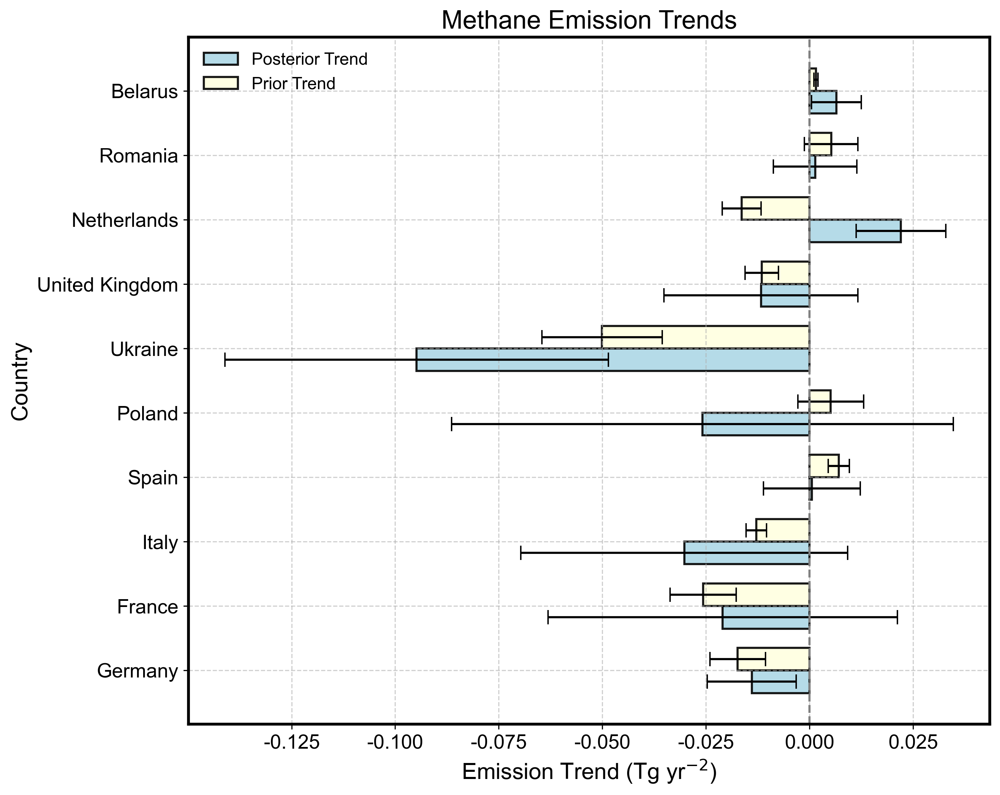

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import statsmodels.api as sm

# -------------------------------
# Step 1
# -------------------------------
file_path = r'F:\Inv_EU\emi_df\TRO_ICOS_828_tro55_C_icosall_0.5_corBD\po_pr_emi_both_std_nomountainv3.csv'
final_df = pd.read_csv(file_path)
df_years = final_df[final_df['year'].between(2019, 2024)].copy()

anthro_sectors = [
    'Coal', 'Rice', 'Landfills', 'Livestock',
    'Wastewater', 'Oil', 'Gas', 'OtherAnth'
]
df_years['pr_anthro_Tg'] = df_years[
    [f'pr_{sector}' for sector in anthro_sectors]
].sum(axis=1) / 1e9

df_years['po_anthro_Tg'] = df_years[
    [f'po_{sector}' for sector in anthro_sectors]
].sum(axis=1) / 1e9

def find_prior_std_column(df, sector):
    candidates = [
        f'pr_std_{sector}',
        f'std_pr_{sector}',
        f'prior_std_{sector}'
    ]
    for col in candidates:
        if col in df.columns:
            return col
    raise KeyError(
        f'没有找到 {sector} 的先验不确定度列，尝试过：{candidates}'
    )

prior_std_columns = [
    find_prior_std_column(df_years, sector)
    for sector in anthro_sectors
]

df_years['pr_anthro_std_Tg'] = np.sqrt(
    df_years[prior_std_columns].pow(2).sum(axis=1)
) / 1e9

# -------------------------------
# Step 2
# -------------------------------
df_2023 = df_years[df_years['year'] == 2023]

top_10_countries_list = (
    df_2023
    .sort_values('po_anthro_Tg', ascending=False)
    .head(10)['name']
    .tolist()
)

# -------------------------------
# Step 3
# -------------------------------
df_top10 = df_years[
    df_years['name'].isin(top_10_countries_list)
].copy()

# -------------------------------
# Step 4
# -------------------------------
trend_data = []

for country, group in df_top10.groupby('name'):
    group = group.sort_values('year')
    X_vals = group['year'].values
    X_design = sm.add_constant(X_vals)

    # Posterior 
    y_vals = group['po_anthro_Tg'].values
    y_errs = group['std'].values

    wls_model = sm.WLS(
        y_vals,
        X_design,
        weights=1 / y_errs**2
    )
    results = wls_model.fit()

    slope = results.params[1]
    slope_stderr = results.bse[1]

    # Prior 
    y_prior = group['pr_anthro_Tg'].values

    slope_prior = np.polyfit(
        X_vals,
        y_prior,
        deg=1
    )[0]

    prior_ols_model = sm.OLS(
        y_prior,
        X_design
    ).fit()

    slope_prior_stderr = prior_ols_model.bse[1]
    
    
    trend_data.append({
        'Country': country,
        'Slope_Prior': slope_prior,
        'Slope_Posterior': slope,
        'Slope_Prior_Std': slope_prior_stderr,
        'Slope_Posterior_Std': slope_stderr
    })

df_trends = pd.DataFrame(trend_data)
df_trends = (
    df_trends
    .set_index('Country')
    .loc[top_10_countries_list]
    .reset_index()
)

# -------------------------------
# Step 5
# -------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

bar_width = 0.35
index = np.arange(len(df_trends))

# Posterior
bars2 = ax.barh(
    index,
    df_trends['Slope_Posterior'],
    bar_width,
    xerr=df_trends['Slope_Posterior_Std'],
    color='#ADD8E6',
    edgecolor='black',
    linewidth=1.5,
    alpha=0.9,
    label='Posterior Trend',
    capsize=5,
    error_kw=dict(lw=1.5)
)

# Prior
bars1 = ax.barh(
    index + bar_width,
    df_trends['Slope_Prior'],
    bar_width,
    xerr=df_trends['Slope_Prior_Std'],
    color='#FFFFE0',
    edgecolor='black',
    linewidth=1.5,
    alpha=0.9,
    label='Prior Trend',
    capsize=5,
    error_kw=dict(lw=1.5)
)

ax.set_yticks(index + bar_width / 2)
ax.set_yticklabels(df_trends['Country'])

ax.legend(frameon=False, fontsize=12, loc='best')

ax.tick_params(axis='both', labelsize=14)

ax.set_xlabel('Emission Trend (Tg yr$^{-2}$)', fontsize=16)
ax.set_ylabel('Country', fontsize=16)

ax.set_title('Methane Emission Trends', fontsize=18)

ax.axvline(0, color='gray', linestyle='--', linewidth=1.5)

ax.grid(True, linestyle='--', alpha=0.6, zorder=0)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()